# Retail Returns Analysis

## Project Introduction

This notebook investigates the question: **How do product returns affect retail sales performance and financial outcomes?** It follows the workflow from data inspection and validation through exploratory analysis and business recommendations.

## Project Overview

This project analyses retail sales, customer purchasing behaviour, product returns and refund patterns to understand their impact on retail sales performance and financial outcomes. It uses a synthetic retail dataset made up of interconnected tables for orders, customers, products, payments and returns.

## Project Objectives

- Analyse overall retail sales performance and trends.
- Understand customer purchasing behaviour and segmentation.
- Evaluate product and category performance.
- Measure product return rates and refund amounts.
- Assess the financial implications of product returns.
- Identify business problems and recommend improvements.

## Project Workflow

1. Phase 1 – Data Inspection and Understanding
2. Phase 2 – Data Cleaning and Validation
3. Phase 3 – Exploratory Data Analysis (EDA)
4. Phase 4 – Business Insights and Recommendations
5. Phase 5 – Final Presentation and Documentation

## Table of Contents

- [Project Introduction](#project-introduction)
- [Project Overview](#project-overview)
- [Project Objectives](#project-objectives)
- [Project Workflow](#project-workflow)
- [Dataset Overview](#dataset-overview)
- [Phase 1 – Data Inspection and Understanding](#phase-1--data-inspection-and-understanding)
  - [Dataset File Inventory and Loading](#dataset-file-inventory-and-loading)
  - [Table Structure and Key Relationships](#table-structure-and-key-relationships)
  - [Table Previews, Data Types, and Missing Values](#table-previews-data-types-and-missing-values)
  - [Contextual Missingness and Status Checks](#contextual-missingness-and-status-checks)
  - [Return, Refund, and Transaction Profiling](#return-refund-and-transaction-profiling)
  - [Table Completeness and Preliminary Sales Patterns](#table-completeness-and-preliminary-sales-patterns)
- [Phase 2 – Data Cleaning and Validation](#phase-2--data-cleaning-and-validation)
  - [Working Copies and Missing-Value Assessment](#working-copies-and-missing-value-assessment)
  - [Missing-Value Interpretation and Treatment](#missing-value-interpretation-and-treatment)
  - [Duplicate Rows and Primary-Key Validation](#duplicate-rows-and-primary-key-validation)
  - [Data Types and Value-Range Checks](#data-types-and-value-range-checks)
  - [Payment and Order-Value Validation](#payment-and-order-value-validation)
  - [Timestamp, Status, and Foreign-Key Validation](#timestamp-status-and-foreign-key-validation)
  - [Transaction Counts and High-Activity Checks](#transaction-counts-and-high-activity-checks)
  - [Return, Refund, Product, and Order Relationships](#return-refund-product-and-order-relationships)
- [Phase 3 – Exploratory Data Analysis (EDA)](#phase-3--exploratory-data-analysis-eda)
  - [Step 1 – Overall Sales Performance](#step-1--overall-sales-performance)
  - [Step 2 – Sales Trends and Seasonality](#step-2--sales-trends-and-seasonality)
  - [Step 3 – Customer Behaviour Analysis](#step-3--customer-behaviour-analysis)
  - [Step 4 – Customer Segmentation and Purchasing Patterns](#step-4--customer-segmentation-and-purchasing-patterns)
  - [Step 5 – Product and Category Performance](#step-5--product-and-category-performance)
  - [Step 6 – Payment and Transaction Analysis](#step-6--payment-and-transaction-analysis)
  - [Step 7 – Returns and Refund Analysis](#step-7--returns-and-refund-analysis)
  - [Step 8 – Cross-Dimensional Analysis](#step-8--cross-dimensional-analysis)
- [Phase 4 – Business Insights and Recommendations](#phase-4--business-insights-and-recommendations)
  - [Consolidated Key Findings](#consolidated-key-findings)
  - [Financial Impact Assessment](#financial-impact-assessment)
  - [Business Problems Identified](#business-problems-identified)
  - [Business Recommendations](#business-recommendations)
  - [Limitations and Conclusion](#limitations-and-conclusion)
- [Phase 5 – Final Presentation and Documentation](#phase-5--final-presentation-and-documentation)
  - [Project Summary](#project-summary)
  - [Key Findings](#key-findings)
  - [Business Recommendations](#business-recommendations-1)
  - [Project Limitations](#project-limitations)
  - [Final Conclusion](#final-conclusion)

## Dataset Overview

### Dataset Description

This project uses a synthetic retail dataset containing multiple interconnected tables. These tables represent different aspects of a retail business, including orders, products, customers, payments and product returns.

The dataset is used to investigate retail sales performance and understand the financial impact of product returns.

### Dataset Tables

| Table | Description |
|---|---|
| Orders | Contains order-level information and order statuses. |
| Order Items | Contains individual products purchased within each order. |
| Products | Contains product-related information. |
| Categories | Contains product category information. |
| Payments | Contains payment transaction records. |
| Returns | Contains returned-item information, refund amounts and restocking details. |

### Dataset Characteristics

- Data type: Synthetic retail data.
- Structure: Multiple related tables.
- Analysis level: Customer, order, product, category and return.
- Main focus: Sales performance, product returns and financial outcomes.

### Research Question

**How do product returns affect retail sales performance and financial outcomes?**

# Phase 1 – Data Inspection and Understanding

This phase focuses on understanding the dataset structure, examining the available tables, identifying relationships between datasets and evaluating the initial quality of the data.

The objective is to understand the data before performing cleaning and analysis.

## Dataset File Inventory and Loading

In [1]:
# List the available Parquet datasets and report each table's dimensions.
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../Dataset")

files = sorted(DATA_DIR.glob("*.parquet"))

print("Number of dataset files:", len(files))

for file in files:
    df = pd.read_parquet(file)
    print(file.name, "→", df.shape)

Number of dataset files: 7
categories.parquet → (24, 3)
customers.parquet → (12000, 9)
order_items.parquet → (215000, 6)
orders.parquet → (90000, 8)
payments.parquet → (95000, 7)
products.parquet → (2000, 7)
returns.parquet → (12000, 6)


## Table Structure and Key Relationships

In [3]:
from pathlib import Path
import pandas as pd

# Locate dataset files
DATA_DIR = Path("../Dataset")
files = sorted(DATA_DIR.glob("*.parquet"))

# Load all seven tables
tables = {
    file.stem: pd.read_parquet(file)
    for file in files
}

# Keep direct references for the later Phase 2 setup cell.
categories = tables["categories"]
customers = tables["customers"]
products = tables["products"]
orders = tables["orders"]
order_items = tables["order_items"]
payments = tables["payments"]
returns = tables["returns"]

# Check primary key uniqueness
primary_keys = {
    "categories": "category_id",
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "payments": "payment_id",
    "returns": "return_id"
}

for table, key in primary_keys.items():
    df = tables[table]
    print(
        table,
        "Unique IDs:", df[key].nunique(),
        "| Total rows:", len(df)
    )

categories Unique IDs: 24 | Total rows: 24
customers Unique IDs: 12000 | Total rows: 12000
products Unique IDs: 2000 | Total rows: 2000
orders Unique IDs: 90000 | Total rows: 90000
order_items Unique IDs: 215000 | Total rows: 215000
payments Unique IDs: 95000 | Total rows: 95000
returns Unique IDs: 12000 | Total rows: 12000


In [3]:
# Check whether foreign keys refer to existing records

relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("products", "category_id", "categories", "category_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("returns", "order_item_id", "order_items", "order_item_id")
]

for child, child_col, parent, parent_col in relationships:

    child_values = set(tables[child][child_col])
    parent_values = set(tables[parent][parent_col])

    unmatched = child_values - parent_values

    print(
        f"{child}.{child_col} → {parent}.{parent_col}:",
        len(unmatched), "unmatched values"
    )

orders.customer_id → customers.customer_id: 0 unmatched values
order_items.order_id → orders.order_id: 0 unmatched values
order_items.product_id → products.product_id: 0 unmatched values
products.category_id → categories.category_id: 0 unmatched values
payments.order_id → orders.order_id: 0 unmatched values
returns.order_item_id → order_items.order_item_id: 0 unmatched values


## Table Previews, Data Types, and Missing Values

In [4]:
# Preview each loaded table and inspect its column data types.
for name, df in tables.items():
    print("\n", "=" * 50)
    print("TABLE:", name)

    display(df.head(5))

    print("\nData types:")
    print(df.dtypes)


TABLE: categories


,category_id,category_name,parent_category_id
0,1,Garden Tools,NaN
1,2,Outdoor Living,NaN
2,3,Plants,NaN
3,4,Irrigation,NaN
4,5,Soil & Compost,NaN



Data types:
category_id             int32
category_name             str
parent_category_id    float64
dtype: object

TABLE: customers


,customer_id,first_name,last_name,email,city,country,signup_date,loyalty_tier,marketing_opt_in
0,1,Delphine,Rossi,delphine.rossi0@example.com,Bristol,GB,2023-02-13,silver,False
1,2,Bruno,Kirby,bruno.kirby1@example.com,Toronto,CA,2023-09-29,NaN,True
2,3,Bianca,Mwangi,bianca.mwangi2@example.com,Raleigh,US,2023-04-11,NaN,True
3,4,Hugo,Kirby,hugo.kirby3@example.com,Norwich,GB,2023-12-27,bronze,True
4,5,Hana,Vogt,hana.vogt4@example.com,Auckland,NZ,2025-06-01,NaN,True



Data types:
customer_id          int32
first_name             str
last_name              str
email                  str
city                   str
country                str
signup_date         object
loyalty_tier           str
marketing_opt_in      bool
dtype: object

TABLE: order_items


,order_item_id,order_id,product_id,quantity,unit_price,discount_amount
0,1,33445,1,1,13.55,0.00
1,2,70002,2,1,25.40,0.00
2,3,12781,20,1,60.52,0.00
3,4,57025,4,1,46.14,0.00
4,5,34619,7,1,51.59,0.00


... (5 outputs left out)

,product_id,sku,product_name,category_id,unit_price,unit_cost,discontinued_at
0,1,SKU-000001,Heritage Steel Trowel,20,13.55,8.55,None
1,2,SKU-000002,Heritage Steel Watering Can,15,25.40,16.84,None
2,3,SKU-000003,Heritage Steel Pruning Shears,1,12.51,7.30,2025-11-01
3,4,SKU-000004,Heritage Steel Compost Bin,16,46.14,24.32,None
4,5,SKU-000005,Heritage Steel Wheelbarrow,19,18.87,12.41,None



Data types:
product_id          int32
sku                   str
product_name          str
category_id         int32
unit_price         object
unit_cost          object
discontinued_at    object
dtype: object

TABLE: returns


,return_id,order_item_id,returned_at,reason,refund_amount,restocked
0,1,210086,2025-07-15 21:39:31,changed_mind,18.87,True
1,2,65856,2025-08-17 17:06:32,damaged,102.70,True
2,3,45963,2023-04-08 18:35:26,not_as_described,63.74,True
3,4,77437,2024-07-24 20:34:59,changed_mind,117.20,True
4,5,191463,2025-03-07 21:33:23,damaged,14.62,True



Data types:
return_id                 int32
order_item_id             int32
returned_at      datetime64[us]
reason                      str
refund_amount            object
restocked                  bool
dtype: object


In [5]:
# Inspect sample values in object columns and summarize missing entries.
for name, df in tables.items():
    print("\nTABLE:", name)

    for col in df.columns:
        if df[col].dtype == "object":
            sample = df[col].dropna()

            if len(sample) > 0:
                print(
                    col,
                    "| Sample:", sample.iloc[0],
                    "| Type:", type(sample.iloc[0]).__name__
                )

    print("Missing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])


TABLE: categories
Missing values:
parent_category_id    6
dtype: int64

TABLE: customers
signup_date | Sample: 2023-02-13 | Type: date
Missing values:
loyalty_tier    5296
dtype: int64

TABLE: order_items
unit_price | Sample: 13.55 | Type: Decimal
discount_amount | Sample: 0.00 | Type: Decimal
Missing values:
Series([], dtype: int64)

TABLE: orders
Missing values:
shipped_at     10769
coupon_code    70285
dtype: int64

TABLE: payments
amount | Sample: 232.03 | Type: Decimal
Missing values:
failure_reason    89748
dtype: int64

TABLE: products
unit_price | Sample: 13.55 | Type: Decimal
unit_cost | Sample: 8.55 | Type: Decimal
discontinued_at | Sample: 2025-11-01 | Type: date
Missing values:
discontinued_at    1847
dtype: int64

TABLE: returns
refund_amount | Sample: 18.87 | Type: Decimal
Missing values:
Series([], dtype: int64)


## Contextual Missingness and Status Checks

In [6]:
# Check why important values are missing

print("ORDER STATUS vs SHIPPING DATE")
print(pd.crosstab(
    tables["orders"]["status"],
    tables["orders"]["shipped_at"].isna()
))

print("\nPAYMENT STATUS vs FAILURE REASON")
print(pd.crosstab(
    tables["payments"]["status"],
    tables["payments"]["failure_reason"].isna()
))

print("\nLOYALTY TIER DISTRIBUTION")
print(tables["customers"]["loyalty_tier"].value_counts(dropna=False))

print("\nPRODUCT DISCONTINUATION")
print(tables["products"]["discontinued_at"].isna().value_counts())

ORDER STATUS vs SHIPPING DATE
shipped_at  False  True 
status                  
cancelled       0   5407
delivered   64897      0
processing      0   5362
returned     4399      0
shipped      9935      0

PAYMENT STATUS vs FAILURE REASON
failure_reason  False  True 
status                      
captured            0  89748
failed           5252      0

LOYALTY TIER DISTRIBUTION
loyalty_tier
NaN       5296
bronze    4023
silver    1992
gold       689
Name: count, dtype: int64

PRODUCT DISCONTINUATION
discontinued_at
True     1847
False     153
Name: count, dtype: int64


## Return, Refund, and Transaction Profiling

In [7]:
# Connect returns to their original orders

return_details = (
    tables["returns"]
    .merge(
        tables["order_items"][["order_item_id", "order_id"]],
        on="order_item_id",
        how="left"
    )
    .merge(
        tables["orders"][["order_id", "status"]],
        on="order_id",
        how="left"
    )
)

print("Return records by original order status:")
print(return_details["status"].value_counts(dropna=False))

print("\nUnique returned order items:",
      return_details["order_item_id"].nunique())

print("Total return records:", len(return_details))

Return records by original order status:
status
delivered     8640
shipped       1323
processing     726
cancelled      693
returned       618
Name: count, dtype: int64

Unique returned order items: 12000
Total return records: 12000


In [8]:
# Compare return timestamps with order dates and summarize timing by status.
print("Return dates before order date:")

date_check = return_details.merge(
    tables["orders"][["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

print(
    (date_check["returned_at"] < date_check["ordered_at"]).sum()
)

print("\nReturn dates by order status:")

print(
    date_check.groupby("status")[
        "returned_at"
    ].agg(["min", "max"])
)

Return dates before order date:
5962

Return dates by order status:
                           min                 max
status                                            
cancelled  2023-01-02 18:44:52 2025-12-31 11:12:11
delivered  2023-01-01 13:58:18 2025-12-31 22:52:37
processing 2023-01-04 19:28:58 2025-12-31 11:48:20
returned   2023-01-01 11:56:26 2025-12-30 03:11:35
shipped    2023-01-02 09:39:46 2025-12-31 20:30:51


In [9]:
# Identify returns occurring before their order dates

invalid_returns = date_check[
    date_check["returned_at"] < date_check["ordered_at"]
].copy()

invalid_returns["date_difference_days"] = (
    invalid_returns["ordered_at"] -
    invalid_returns["returned_at"]
).dt.days

display(
    invalid_returns[
        [
            "order_id",
            "order_item_id",
            "status",
            "ordered_at",
            "returned_at",
            "date_difference_days"
        ]
    ].head(10)
)

,order_id,order_item_id,status,ordered_at,returned_at,date_difference_days
5,8894,54087,delivered,2025-12-13 18:41:31,2024-07-29 17:41:00,502
6,38483,52262,delivered,2025-01-13 18:57:54,2024-10-26 00:15:12,79
8,12619,11572,delivered,2025-06-10 21:45:45,2023-10-10 13:35:34,609
10,43537,150865,delivered,2024-09-03 14:31:17,2023-05-05 09:00:10,487
13,88752,29517,delivered,2024-11-03 16:38:33,2023-06-26 11:04:02,496
14,25634,102841,delivered,2025-03-31 16:56:26,2023-06-08 17:52:27,661
16,59186,198274,delivered,2025-09-03 10:41:00,2023-09-15 14:05:31,718
17,41332,124720,delivered,2024-04-01 08:33:54,2024-02-27 19:47:11,33
24,41586,24743,cancelled,2024-10-20 15:00:09,2024-04-05 17:20:16,197
26,27617,42336,delivered,2024-11-29 03:42:02,2023-01-19 21:05:14,679


In [10]:
# Quantify pre-order return timestamps and summarize affected records by status.
print("Total return records:", len(date_check))

print("Invalid return dates:",
      (date_check["returned_at"] < date_check["ordered_at"]).sum())

print("\nPercentage of invalid records:",
      round(
          (date_check["returned_at"] < date_check["ordered_at"]).mean() * 100,
          2
      ), "%")

print("\nInvalid records by order status:")

print(
    invalid_returns["status"].value_counts()
)

Total return records: 12000
Invalid return dates: 5962

Percentage of invalid records: 49.68 %

Invalid records by order status:
status
delivered     4296
shipped        646
processing     376
cancelled      349
returned       295
Name: count, dtype: int64


In [11]:
# Summarize return reasons and whether returned items were restocked.
print("Return reason distribution:")

print(
    tables["returns"]["reason"].value_counts(
        dropna=False
    )
)

print("\nRestocking distribution:")

print(
    tables["returns"]["restocked"].value_counts(
        dropna=False
    )
)

Return reason distribution:
reason
changed_mind        3739
damaged             3384
not_as_described    2862
wrong_item          2015
Name: count, dtype: int64

Restocking distribution:
restocked
True     8538
False    3462
Name: count, dtype: int64


In [12]:
# Merge returns with their original order item details

refund_check = tables["returns"].merge(
    tables["order_items"][
        ["order_item_id", "product_id", "quantity",
         "unit_price", "discount_amount"]
    ],
    on="order_item_id",
    how="left"
)

# Calculate original item value after discount
refund_check["item_value"] = (
    refund_check["quantity"] * refund_check["unit_price"]
    - refund_check["discount_amount"]
)

# Calculate refund percentage
refund_check["refund_percentage"] = (
    refund_check["refund_amount"] /
    refund_check["item_value"] * 100
)

display(refund_check[
    ["order_item_id", "quantity", "unit_price",
     "discount_amount", "item_value",
     "refund_amount", "refund_percentage"]
].head(10))

,order_item_id,quantity,unit_price,discount_amount,item_value,refund_amount,refund_percentage
0,210086,1,18.87,0.00,18.87,18.87,100
1,65856,2,51.35,0.00,102.70,102.70,100
2,45963,2,31.87,0.00,63.74,63.74,100
3,77437,2,58.60,0.00,117.20,117.20,100
4,191463,1,14.62,0.00,14.62,14.62,100
5,54087,1,10.74,0.00,10.74,10.74,100
6,52262,3,21.04,2.99,60.13,63.12,104.9725594545152170297688342
7,51778,1,23.81,0.00,23.81,23.81,100
8,11572,1,13.55,0.00,13.55,13.55,100
9,81945,1,21.84,0.00,21.84,21.84,100


In [13]:
# Overall refund statistics

print("Average refund percentage:",
      round(float(refund_check["refund_percentage"].mean()), 2), "%")

print("\nRefund percentage summary:")
print(refund_check["refund_percentage"].describe())

# Count refunds above, equal to and below item value

print("\nRefund comparison:")

print("Above 100%:",
      (refund_check["refund_percentage"] > 100).sum())

print("Exactly 100%:",
      (refund_check["refund_percentage"] == 100).sum())

print("Below 100%:",
      (refund_check["refund_percentage"] < 100).sum())

# Check invalid item values
print("\nZero or negative item values:",
      (refund_check["item_value"] <= 0).sum())

Average refund percentage: 101.36 %

Refund percentage summary:
count     12000
unique     1736
top         100
freq      10151
Name: refund_percentage, dtype: object

Refund comparison:
Above 100%: 1849
Exactly 100%: 10151
Below 100%: 0

Zero or negative item values: 0


## Table Completeness and Preliminary Sales Patterns

In [14]:
# Review columns, missing-value counts, and duplicate rows in each source file.
for file in files:
    df = pd.read_parquet(file)

    print("\n", "=" * 50)
    print("TABLE:", file.name)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


TABLE: categories.parquet

Column names:
['category_id', 'category_name', 'parent_category_id']

Missing values:
category_id           0
category_name         0
parent_category_id    6
dtype: int64

Duplicate rows: 0

TABLE: customers.parquet

Column names:
['customer_id', 'first_name', 'last_name', 'email', 'city', 'country', 'signup_date', 'loyalty_tier', 'marketing_opt_in']

Missing values:
customer_id            0
first_name             0
last_name              0
email                  0
city                   0
country                0
signup_date            0
loyalty_tier        5296
marketing_opt_in       0
dtype: int64

Duplicate rows: 0

TABLE: order_items.parquet

Column names:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount']

Missing values:
order_item_id      0
order_id           0
product_id         0
quantity           0
unit_price         0
discount_amount    0
dtype: int64

Duplicate rows: 0

TABLE: orders.parquet

Column names:


In [15]:
# Combine order items with product and category details
category_data = (
    tables["order_items"]
    .merge(
        tables["products"][["product_id", "category_id"]],
        on="product_id",
        how="left"
    )
    .merge(
        tables["categories"][["category_id", "category_name"]],
        on="category_id",
        how="left"
    )
)

# Count total items sold in each category
total_items = (
    category_data.groupby("category_name")["order_item_id"]
    .nunique()
)

# Count returned items in each category
returned_data = (
    tables["returns"]
    .merge(
        category_data[["order_item_id", "category_name"]],
        on="order_item_id",
        how="left"
    )
)

returned_items = (
    returned_data.groupby("category_name")["order_item_id"]
    .nunique()
)

# Calculate return rate
category_returns = pd.DataFrame({
    "Total Items Sold": total_items,
    "Returned Items": returned_items
}).fillna(0)

category_returns["Return Rate (%)"] = (
    category_returns["Returned Items"] /
    category_returns["Total Items Sold"] * 100
)

# Display highest return rates first
category_returns = category_returns.sort_values(
    "Return Rate (%)", ascending=False
)

category_returns

,Total Items Sold,Returned Items,Return Rate (%)
category_name,,,
Sprinklers,3422,209,6.107539
Lighting,3420,207,6.052632
Drip Systems,3414,205,6.004687
Bagged Soil,14589,847,5.805744
Soil & Compost,3739,217,5.803691
Plants,5309,308,5.801469
Garden Tools,21088,1220,5.785281
Shrubs,4097,235,5.735904
Fire Pits,12337,700,5.673989


In [16]:
# Combine order items with order details
sales_data = tables["order_items"].merge(
    tables["orders"][["order_id", "ordered_at", "status"]],
    on="order_id",
    how="left"
)

# Exclude cancelled orders
sales_data = sales_data[
    sales_data["status"] != "cancelled"
].copy()

# Calculate item value after discount
sales_data["sales_value"] = (
    sales_data["quantity"] * sales_data["unit_price"]
    - sales_data["discount_amount"]
)

# Convert order date into datetime format
sales_data["ordered_at"] = pd.to_datetime(
    sales_data["ordered_at"]
)

# Extract month and year
sales_data["month"] = (
    sales_data["ordered_at"].dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    sales_data.groupby("month")["sales_value"]
    .sum()
    .reset_index()
)

monthly_sales

,month,sales_value
0,2023-01,234941.56
1,2023-02,183614.74
2,2023-03,215550.53
3,2023-04,204517.39
4,2023-05,217218.54
5,2023-06,197110.50
6,2023-07,212849.04
7,2023-08,214641.32
8,2023-09,192816.04
9,2023-10,214375.12


In [17]:
category_data = (
    tables["order_items"]
    .merge(
        tables["products"][["product_id", "category_id"]],
        on="product_id"
    )
    .merge(
        tables["categories"][["category_id", "category_name"]],
        on="category_id"
    )
    .merge(
        tables["orders"][["order_id", "status"]],
        on="order_id"
    )
)

# Exclude cancelled orders
category_data = category_data[
    category_data["status"] != "cancelled"
]

total_items = category_data.groupby(
    "category_name"
)["order_item_id"].nunique()

returned_data = tables["returns"].merge(
    category_data[["order_item_id", "category_name"]],
    on="order_item_id",
    how="inner"
)

returned_items = returned_data.groupby(
    "category_name"
)["order_item_id"].nunique()

category_returns = pd.DataFrame({
    "Total Non-Cancelled Items": total_items,
    "Returned Items": returned_items
})

category_returns["Return Rate (%)"] = (
    category_returns["Returned Items"] /
    category_returns["Total Non-Cancelled Items"] * 100
)

category_returns = category_returns.sort_values(
    "Return Rate (%)", ascending=False
)

category_returns

,Total Non-Cancelled Items,Returned Items,Return Rate (%)
category_name,,,
Lighting,3207,199,6.205176
Sprinklers,3214,196,6.098320
Drip Systems,3215,196,6.096423
Garden Tools,19860,1168,5.881168
Bagged Soil,13757,807,5.866105
Shrubs,3852,224,5.815161
Soil & Compost,3515,204,5.803698
Plants,4974,287,5.770004
Fire Pits,11592,666,5.745342


# Phase 2 – Data Cleaning and Validation

This phase focuses on preparing the dataset for analysis by checking data types, missing values, duplicates, inconsistent records and relationships between tables.

Validation checks are performed to identify potential data-quality issues and ensure the dataset is suitable for further analysis.

## Working Copies and Missing-Value Assessment

In [4]:

# PHASE 2: DATA CLEANING AND PROCESSING

# Create independent working copies of the seven tables
# already loaded during Phase 1.

clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("Working copies created successfully!")

# Display the dimensions of each working table.
for name, df in clean_tables.items():
    print(name, df.shape)


Working copies created successfully!
categories (24, 3)
customers (12000, 9)
order_items (215000, 6)
orders (90000, 8)
payments (95000, 7)
products (2000, 7)
returns (12000, 6)


In [ ]:
# Inspect variables currently present in the notebook kernel.
%whos


Variable           Type           Data/Info
-------------------------------------------
DATA_DIR           WindowsPath    ..\Dataset
Path               type           <class 'pathlib._local.Path'>
category_data      DataFrame      Shape: (202171, 9)
category_returns   DataFrame      Shape: (24, 3)
child              str            returns
child_col          str            order_item_id
child_values       set            {32768, 163841, 3, 196616<...>60, 196595, 98294, 65529}
col                str            restocked
date_check         DataFrame      Shape: (12000, 9)
df                 DataFrame      Shape: (12000, 6)
files              list           n=7
invalid_returns    DataFrame      Shape: (5962, 10)
key                str            return_id
monthly_sales      DataFrame      Shape: (36, 2)
name               str            returns
parent             str            order_items
parent_col         str            order_item_id
parent_values      set            {1, 2, 3, 4, 5, 6, 7

In [ ]:
# Report the row and column counts for each loaded table.
for name, df in tables.items():
    print(name, df.shape)

categories (24, 3)
customers (12000, 9)
order_items (215000, 6)
orders (90000, 8)
payments (95000, 7)
products (2000, 7)
returns (12000, 6)


In [ ]:
# Create independent working copies so validation does not alter source tables.
clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("Working copies created successfully!")

for name, df in clean_tables.items():
    print(name, df.shape)

Working copies created successfully!
categories (24, 3)
customers (12000, 9)
order_items (215000, 6)
orders (90000, 8)
payments (95000, 7)
products (2000, 7)
returns (12000, 6)


In [ ]:
# Show missing-value counts for columns that contain missing data.
for name, df in clean_tables.items():
    print(f"\n{name.upper()}")
    print(df.isnull().sum()[df.isnull().sum() > 0])


CATEGORIES
parent_category_id    6
dtype: int64

CUSTOMERS
loyalty_tier    5296
dtype: int64

ORDER_ITEMS
Series([], dtype: int64)

ORDERS
shipped_at     10769
coupon_code    70285
dtype: int64

PAYMENTS
failure_reason    89748
dtype: int64

PRODUCTS
discontinued_at    1847
dtype: int64

RETURNS
Series([], dtype: int64)


## Missing-Value Interpretation and Treatment

In [ ]:
# 1. Category hierarchy
print("CATEGORY PARENT IDs:")
print(clean_tables["categories"]["parent_category_id"].value_counts(dropna=False))

# 2. Customer loyalty tiers
print("\nCUSTOMER LOYALTY TIERS:")
print(clean_tables["customers"]["loyalty_tier"].value_counts(dropna=False))

# 3. Shipping dates against order status
print("\nSHIPPING DATE BY ORDER STATUS:")
print(pd.crosstab(
    clean_tables["orders"]["status"],
    clean_tables["orders"]["shipped_at"].isna()
))

# 4. Coupon usage
print("\nCOUPON CODE:")
print(clean_tables["orders"]["coupon_code"].value_counts(dropna=False))

# 5. Payment failure reasons
print("\nPAYMENT FAILURE REASONS:")
print(pd.crosstab(
    clean_tables["payments"]["status"],
    clean_tables["payments"]["failure_reason"].isna()
))

# 6. Product discontinuation dates
print("\nPRODUCT DISCONTINUATION:")
print(clean_tables["products"]["discontinued_at"].isna().value_counts())

CATEGORY PARENT IDs:
parent_category_id
6.0    8
NaN    6
4.0    4
3.0    3
2.0    2
1.0    1
Name: count, dtype: int64

CUSTOMER LOYALTY TIERS:
loyalty_tier
NaN       5296
bronze    4023
silver    1992
gold       689
Name: count, dtype: int64

SHIPPING DATE BY ORDER STATUS:
shipped_at  False  True 
status                  
cancelled       0   5407
delivered   64897      0
processing      0   5362
returned     4399      0
shipped      9935      0

COUPON CODE:
coupon_code
NaN       70285
SAVE22      606
SAVE21      596
SAVE28      584
SAVE34      577
SAVE5       571
SAVE39      566
SAVE38      563
SAVE31      561
SAVE32      560
SAVE40      559
SAVE16      558
SAVE12      552
SAVE9       552
SAVE18      550
SAVE7       549
SAVE25      548
SAVE11      548
SAVE8       547
SAVE26      546
SAVE20      546
SAVE17      545
SAVE6       544
SAVE19      539
SAVE33      539
SAVE37      538
SAVE24      536
SAVE35      535
SAVE36      535
SAVE27      530
SAVE14      527
SAVE10      526
SAVE13     

In [ ]:
# Document why these missing values are retained rather than imputed.
import pandas as pd
missing_treatment = pd.DataFrame({
    "Column": [
        "parent_category_id",
        "loyalty_tier",
        "shipped_at",
        "coupon_code",
        "failure_reason",
        "discontinued_at"
    ],
    "Treatment": [
        "Retained - top-level category",
        "Retained - tier not assigned",
        "Retained - not shipped",
        "Retained - no coupon applied",
        "Retained - successful payment",
        "Retained - no discontinuation date"
    ]
})

print(missing_treatment)

               Column                           Treatment
0  parent_category_id       Retained - top-level category
1        loyalty_tier        Retained - tier not assigned
2          shipped_at              Retained - not shipped
3         coupon_code        Retained - no coupon applied
4      failure_reason       Retained - successful payment
5     discontinued_at  Retained - no discontinuation date


In [ ]:
# Confirm the expected Parquet files are available in the dataset directory.
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../Dataset")

print("Dataset files:")
print(list(DATA_DIR.glob("*.parquet")))

Dataset files:
[WindowsPath('../Dataset/categories.parquet'), WindowsPath('../Dataset/customers.parquet'), WindowsPath('../Dataset/orders.parquet'), WindowsPath('../Dataset/order_items.parquet'), WindowsPath('../Dataset/payments.parquet'), WindowsPath('../Dataset/products.parquet'), WindowsPath('../Dataset/returns.parquet')]


### Reloading Source Tables for Validation

In [ ]:
# Load each Parquet file into the tables dictionary and report its dimensions.
tables = {
    file.stem: pd.read_parquet(file)
    for file in DATA_DIR.glob("*.parquet")
}

print("All tables loaded successfully!\n")

for name, df in tables.items():
    print(name, df.shape)

All tables loaded successfully!

categories (24, 3)
customers (12000, 9)
orders (90000, 8)
order_items (215000, 6)
payments (95000, 7)
products (2000, 7)
returns (12000, 6)


In [ ]:
# Create working copies of all loaded source tables.

clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("All seven working copies created!")

All seven working copies created!


In [ ]:
# Recreate working copies for the current validation pass.
clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("All seven working copies created!")

All seven working copies created!


In [ ]:
# Compare total missing-value counts across the working tables.
for name, df in clean_tables.items():
    print(name, "Missing values:", df.isnull().sum().sum())

categories Missing values: 6
customers Missing values: 5296
orders Missing values: 81054
order_items Missing values: 0
payments Missing values: 89748
products Missing values: 1847
returns Missing values: 0


## Duplicate Rows and Primary-Key Validation

In [ ]:
# Count fully duplicated rows in each working table.
for name, df in clean_tables.items():
    duplicates = df.duplicated().sum()

    print(f"{name}: {duplicates} duplicate rows")

categories: 0 duplicate rows
customers: 0 duplicate rows
orders: 0 duplicate rows
order_items: 0 duplicate rows
payments: 0 duplicate rows
products: 0 duplicate rows
returns: 0 duplicate rows


In [ ]:
# PHASE 2: Step 4: DUPLICATE CHECKING

primary_key_columns = {
    "categories": "category_id",
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "payments": "payment_id",
    "returns": "return_id"
}

for name, column in primary_key_columns.items():
    duplicates = clean_tables[name][column].duplicated().sum()

    print(f"{name}: {duplicates} duplicate {column}")

categories: 0 duplicate category_id
customers: 0 duplicate customer_id
products: 0 duplicate product_id
orders: 0 duplicate order_id
order_items: 0 duplicate order_item_id
payments: 0 duplicate payment_id
returns: 0 duplicate return_id


## Data Types and Value-Range Checks

In [ ]:
# Review current data types for every column in each working table.
for name, df in clean_tables.items():
    print(f"\n{name.upper()}")
    print(df.dtypes)


CATEGORIES
category_id             int32
category_name             str
parent_category_id    float64
dtype: object

CUSTOMERS
customer_id          int32
first_name             str
last_name              str
email                  str
city                   str
country                str
signup_date         object
loyalty_tier           str
marketing_opt_in      bool
dtype: object

ORDERS
order_id                     int32
customer_id                  int32
ordered_at          datetime64[us]
shipped_at          datetime64[us]
status                         str
channel                        str
shipping_country               str
coupon_code                    str
dtype: object

ORDER_ITEMS
order_item_id       int32
order_id            int32
product_id          int32
quantity            int32
unit_price         object
discount_amount    object
dtype: object

PAYMENTS
payment_id                 int32
order_id                   int32
method                       str
amount                

In [ ]:
# Inspect representative values and native Python types for selected columns.
columns_to_check = {
    "categories": ["parent_category_id"],
    "customers": ["signup_date"],
    "order_items": ["unit_price", "discount_amount"],
    "payments": ["amount"],
    "products": ["unit_price", "unit_cost", "discontinued_at"],
    "returns": ["refund_amount"]
}

for table, columns in columns_to_check.items():
    print(f"\n{table.upper()}")

    for column in columns:
        series = clean_tables[table][column].dropna()

        print(f"\n{column}")
        print("Sample values:", series.head(5).tolist())
        print("Actual Python type:", type(series.iloc[0]).__name__ if len(series) else "No values")


CATEGORIES

parent_category_id
Sample values: [3.0, 6.0, 2.0, 6.0, 4.0]
Actual Python type: float64

CUSTOMERS

signup_date
Sample values: [datetime.date(2023, 2, 13), datetime.date(2023, 9, 29), datetime.date(2023, 4, 11), datetime.date(2023, 12, 27), datetime.date(2025, 6, 1)]
Actual Python type: date

ORDER_ITEMS

unit_price
Sample values: [Decimal('13.55'), Decimal('25.40'), Decimal('60.52'), Decimal('46.14'), Decimal('51.59')]
Actual Python type: Decimal

discount_amount
Sample values: [Decimal('0.00'), Decimal('0.00'), Decimal('0.00'), Decimal('0.00'), Decimal('0.00')]
Actual Python type: Decimal

PAYMENTS

amount
Sample values: [Decimal('232.03'), Decimal('27.41'), Decimal('42.16'), Decimal('205.25'), Decimal('120.47')]
Actual Python type: Decimal

PRODUCTS

unit_price
Sample values: [Decimal('13.55'), Decimal('25.40'), Decimal('12.51'), Decimal('46.14'), Decimal('18.87')]
Actual Python type: Decimal

unit_cost
Sample values: [Decimal('8.55'), Decimal('16.84'), Decimal('7.30'),

In [ ]:
#PHASE 2: Step 5 : CORRECT DATA TYPES

# Convert parent_category_id to nullable integer
clean_tables["categories"]["parent_category_id"] = (
    clean_tables["categories"]["parent_category_id"].astype("Int32")
)

# Convert date columns to pandas datetime
clean_tables["customers"]["signup_date"] = pd.to_datetime(
    clean_tables["customers"]["signup_date"]
)

clean_tables["products"]["discontinued_at"] = pd.to_datetime(
    clean_tables["products"]["discontinued_at"]
)

print("Necessary data type conversions completed!")

Necessary data type conversions completed!


In [ ]:
# Verify data types after the date and nullable-integer conversions.
for name, df in clean_tables.items():
    print(f"\n{name.upper()}")
    print(df.dtypes)


CATEGORIES
category_id           int32
category_name           str
parent_category_id    Int32
dtype: object

CUSTOMERS
customer_id                 int32
first_name                    str
last_name                     str
email                         str
city                          str
country                       str
signup_date         datetime64[s]
loyalty_tier                  str
marketing_opt_in             bool
dtype: object

ORDERS
order_id                     int32
customer_id                  int32
ordered_at          datetime64[us]
shipped_at          datetime64[us]
status                         str
channel                        str
shipping_country               str
coupon_code                    str
dtype: object

ORDER_ITEMS
order_item_id       int32
order_id            int32
product_id          int32
quantity            int32
unit_price         object
discount_amount    object
dtype: object

PAYMENTS
payment_id                 int32
order_id                   int3

In [ ]:
# Check quantity
print("Zero or negative quantities:",
      (clean_tables["order_items"]["quantity"] <= 0).sum())

# Check monetary columns
money_columns = {
    "order_items": ["unit_price", "discount_amount"],
    "payments": ["amount"],
    "products": ["unit_price", "unit_cost"],
    "returns": ["refund_amount"]
}

for table, columns in money_columns.items():
    for column in columns:
        values = clean_tables[table][column].dropna()

        negative = sum(value < 0 for value in values)
        zero = sum(value == 0 for value in values)

        print(f"{table}.{column}: Negative={negative}, Zero={zero}")

Zero or negative quantities: 0
order_items.unit_price: Negative=0, Zero=0
order_items.discount_amount: Negative=0, Zero=182669
payments.amount: Negative=0, Zero=1313
products.unit_price: Negative=0, Zero=0
products.unit_cost: Negative=0, Zero=0
returns.refund_amount: Negative=0, Zero=0


## Payment and Order-Value Validation

In [ ]:
# Examine zero-amount payments by status, method, and sample record.
payments = clean_tables["payments"]

zero_payments = payments[payments["amount"] == 0]

print("Zero payment records:", len(zero_payments))

print("\nPayment status:")
print(zero_payments["status"].value_counts())

print("\nPayment methods:")
print(zero_payments["method"].value_counts())

print("\nSample records:")
print(zero_payments.head(10))

Zero payment records: 1313

Payment status:
status
captured    1240
failed        73
Name: count, dtype: int64

Payment methods:
method
card             886
paypal           233
bank_transfer    108
gift_card         86
Name: count, dtype: int64

Sample records:
     payment_id  order_id  method amount             paid_at    status  \
157         158     72006  paypal   0.00 2023-05-04 19:12:58  captured   
226         227     71806    card   0.00 2023-10-25 20:46:22  captured   
248         249     61662    card   0.00 2023-10-01 17:29:44  captured   
546         547     39404  paypal   0.00 2025-11-02 16:20:32  captured   
585         586     35849    card   0.00 2023-06-11 09:22:50  captured   
620         621     73624    card   0.00 2025-01-13 01:17:12  captured   
682         683     82002    card   0.00 2025-11-28 18:55:52  captured   
705         706     56289    card   0.00 2023-12-21 19:59:54  captured   
706         707     32619  paypal   0.00 2023-12-14 17:23:55    failed 

In [ ]:
# Calculate the total item value for each order
items = clean_tables["order_items"].copy()

items["item_value"] = items.apply(
    lambda row: row["quantity"] * row["unit_price"]
    - row["discount_amount"],
    axis=1
)

order_values = (
    items.groupby("order_id")["item_value"]
    .sum()
    .reset_index(name="order_item_value")
)

# Merge zero payments with order values and order status
zero_payment_check = (
    zero_payments
    .merge(order_values, on="order_id", how="left")
    .merge(
        clean_tables["orders"][["order_id", "status"]],
        on="order_id",
        how="left"
    )
)

print("Zero payment status vs order status:")
print(pd.crosstab(
    zero_payment_check["status_y"],
    zero_payment_check["status_x"]
))

print("\nCaptured zero payments with positive order value:")
print((
    (zero_payment_check["status_x"] == "captured") &
    (zero_payment_check["order_item_value"] > 0)
).sum())

print("\nSample:")
print(zero_payment_check.head(10))

NameError: name 'clean_tables' is not defined

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../Dataset")

tables = {
    file.stem: pd.read_parquet(file)
    for file in DATA_DIR.glob("*.parquet")
}

clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

# Restore Phase 2 data type conversions
clean_tables["categories"]["parent_category_id"] = (
    clean_tables["categories"]["parent_category_id"].astype("Int32")
)

clean_tables["customers"]["signup_date"] = pd.to_datetime(
    clean_tables["customers"]["signup_date"]
)

clean_tables["products"]["discontinued_at"] = pd.to_datetime(
    clean_tables["products"]["discontinued_at"]
)

In [ ]:
# Calculate discounted order-item values and aggregate them to order totals.
items = clean_tables["order_items"].copy()

items["item_value"] = (
    items["quantity"] * items["unit_price"]
    - items["discount_amount"]
)

order_values = (
    items.groupby("order_id")["item_value"]
    .sum()
    .reset_index(name="order_item_value")
)

In [ ]:
# Match zero-amount payments to their order values and order statuses.
zero_payments = clean_tables["payments"][
    clean_tables["payments"]["amount"] == 0
].copy()

zero_payment_check = (
    zero_payments[
        ["payment_id", "order_id", "amount", "status"]
    ]
    .rename(columns={"status": "payment_status"})
    .merge(order_values, on="order_id", how="left")
    .merge(
        clean_tables["orders"][["order_id", "status"]]
        .rename(columns={"status": "order_status"}),
        on="order_id",
        how="left"
    )
)

print("Payment status vs order status:")
print(pd.crosstab(
    zero_payment_check["order_status"],
    zero_payment_check["payment_status"]
))

print("\nCaptured zero payments with positive order value:")

print((
    (zero_payment_check["payment_status"] == "captured") &
    (zero_payment_check["order_item_value"] > 0)
).sum())

Payment status vs order status:
payment_status  captured  failed
order_status                    
cancelled             60       4
delivered            918      54
processing            85       3
returned              55       5
shipped              122       7

Captured zero payments with positive order value:
0


In [ ]:
# Check whether any aggregated order-item values are zero or negative.
print("Zero-value orders:",
      (order_values["order_item_value"] == 0).sum())

print("Negative-value orders:",
      (order_values["order_item_value"] < 0).sum())

print("\nMinimum order item value:")
print(order_values["order_item_value"].min())

Zero-value orders: 0
Negative-value orders: 0

Minimum order item value:
2.39


In [ ]:
# Summarize whether zero-payment records have matching order values.
print("Total zero-payment records:",
      len(zero_payment_check))

print("\nMissing order values:",
      zero_payment_check["order_item_value"].isna().sum())

print("\nMatched order values:")
print(zero_payment_check["order_item_value"].head(10))

print("\nZero-payment sample:")
print(zero_payment_check.head(10))

Total zero-payment records: 1313

Missing order values: 1313

Matched order values:
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
Name: order_item_value, dtype: object

Zero-payment sample:
   payment_id  order_id amount payment_status order_item_value order_status
0         158     72006   0.00       captured              NaN   processing
1         227     71806   0.00       captured              NaN    delivered
2         249     61662   0.00       captured              NaN   processing
3         547     39404   0.00       captured              NaN    delivered
4         586     35849   0.00       captured              NaN    delivered
5         621     73624   0.00       captured              NaN    delivered
6         683     82002   0.00       captured              NaN    delivered
7         706     56289   0.00       captured              NaN    delivered
8         707     32619   0.00         failed              NaN    delivered
9     

In [ ]:
# Check whether zero-payment order IDs have corresponding order-item totals.
print("Total unique orders in order_items:",
      clean_tables["order_items"]["order_id"].nunique())

print("\nZero-payment orders found in order_items:")

print(
    zero_payments["order_id"].isin(
        order_values["order_id"]
    ).sum()
)

print("\nZero-payment orders NOT found in order_items:")

print(
    (~zero_payments["order_id"].isin(
        order_values["order_id"]
    )).sum()
)

Total unique orders in order_items: 88758

Zero-payment orders found in order_items:
0

Zero-payment orders NOT found in order_items:
1313


In [ ]:
# Compare payment statuses of zero-amount orders with their order records.
print("Unique zero-payment order IDs:",
      zero_payments["order_id"].nunique())

print("\nZero-payment orders present in orders table:")

print(
    zero_payments["order_id"].isin(
        clean_tables["orders"]["order_id"]
    ).sum()
)

print("\nOrders without any order items:")

print(
    (~clean_tables["orders"]["order_id"].isin(
        clean_tables["order_items"]["order_id"]
    )).sum()
)

Unique zero-payment order IDs: 1240

Zero-payment orders present in orders table:
1313

Orders without any order items:
1242


In [ ]:
# Identify orders without item rows and distinguish zero-payment orders.
zero_payment_order_ids = set(zero_payments["order_id"])

orders_without_items = set(
    clean_tables["orders"]["order_id"]
) - set(
    clean_tables["order_items"]["order_id"]
)

print("Zero-payment orders without items:",
      len(zero_payment_order_ids & orders_without_items))

print("Zero-payment orders with items:",
      len(zero_payment_order_ids - orders_without_items))

print("Other orders without items:",
      len(orders_without_items - zero_payment_order_ids))

Zero-payment orders without items: 1240
Zero-payment orders with items: 0
Other orders without items: 2


In [ ]:
# Check whether any item discount exceeds the pre-discount item value.
item_check = clean_tables["order_items"].copy()

item_check["original_value"] = (
    item_check["quantity"] * item_check["unit_price"]
)

print("Discounts greater than original item value:",
      (item_check["discount_amount"] >
       item_check["original_value"]).sum())

Discounts greater than original item value: 0


In [ ]:
# Count orders with multiple payment records and find the maximum count.
payment_counts = (
    clean_tables["payments"]
    .groupby("order_id")
    .size()
)

print("Orders with multiple payment records:",
      (payment_counts > 1).sum())

print("\nMaximum payment records for one order:",
      payment_counts.max())

Orders with multiple payment records: 5230

Maximum payment records for one order: 2


In [ ]:
# Inspect payment-status combinations for orders with multiple records.
multiple_payments = (
    clean_tables["payments"]
    .groupby("order_id")["status"]
    .agg(list)
)

print(
    multiple_payments[
        multiple_payments.apply(len) > 1
    ].value_counts()
)

status
[failed, captured]    2615
[captured, failed]    2615
Name: count, dtype: int64


## Timestamp, Status, and Foreign-Key Validation

In [ ]:
# Check missing timestamps

print("Missing order timestamps:")
print(clean_tables["orders"]["ordered_at"].isnull().sum())

print("\nMissing payment timestamps:")
print(clean_tables["payments"]["paid_at"].isnull().sum())

print("\nColumn data types:")
print(clean_tables["orders"]["ordered_at"].dtype)
print(clean_tables["payments"]["paid_at"].dtype)

Missing order timestamps:
0

Missing payment timestamps:
0

Column data types:
datetime64[us]
datetime64[us]


In [ ]:
# Combine orders and payment details

payment_check = clean_tables["payments"].merge(
    clean_tables["orders"][["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

# Check payments recorded before orders

invalid_payments = (
    payment_check["paid_at"] < payment_check["ordered_at"]
)

print("Payments before order:")
print(invalid_payments.sum())

Payments before order:
0


In [ ]:
# List the available columns in the orders table.
print(clean_tables["orders"].columns.tolist())

['order_id', 'customer_id', 'ordered_at', 'shipped_at', 'status', 'channel', 'shipping_country', 'coupon_code']


In [ ]:
# Review order-status counts used in the cancellation checks.
print(clean_tables["orders"]["status"].value_counts())

status
delivered     64897
shipped        9935
cancelled      5407
processing     5362
returned       4399
Name: count, dtype: int64


In [ ]:
# List the available columns in the payments table.
print(clean_tables["payments"].columns.tolist())

['payment_id', 'order_id', 'method', 'amount', 'paid_at', 'status', 'failure_reason']


In [ ]:
# Summarize payment statuses in the cancelled-order check.
print(cancelled_payments["status"].value_counts())

status
captured    5394
failed       337
Name: count, dtype: int64


In [ ]:
# Connect returns with their original orders

return_check = clean_tables["returns"].merge(
    clean_tables["order_items"][["order_item_id", "order_id"]],
    on="order_item_id",
    how="left"
).merge(
    clean_tables["orders"][["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

# Check invalid return dates

invalid_returns = (
    return_check["returned_at"] < return_check["ordered_at"]
)

print("Returns before order:")
print(invalid_returns.sum())

Returns before order:
5962


In [ ]:
# Display the count of returns timestamped before their order dates.
print("Returns before order:")
print(invalid_returns.sum())

Returns before order:
5962


In [ ]:
# Connect payments with their original orders

payment_date_check = clean_tables["payments"].merge(
    clean_tables["orders"][["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

# Check payments before order

invalid_payments = (
    payment_date_check["paid_at"] <
    payment_date_check["ordered_at"]
)

print("Payments before order:")
print(invalid_payments.sum())

Payments before order:
0


In [ ]:
# Check shipment before order

invalid_shipments = (
    clean_tables["orders"]["shipped_at"] <
    clean_tables["orders"]["ordered_at"]
)

print("Shipments before order:")
print(invalid_shipments.sum())

Shipments before order:
0


In [ ]:
# Check for shipment dates on cancelled or processing orders.
invalid_shipment_status = (
    clean_tables["orders"]["shipped_at"].notna() &
    clean_tables["orders"]["status"].isin(
        ["cancelled", "processing"]
    )
)

print("Cancelled/processing orders with shipment dates:")
print(invalid_shipment_status.sum())

Cancelled/processing orders with shipment dates:
0


In [ ]:
# Validate the main foreign-key links across related datasets.
relationships = {
    "products.category_id": (
        "products", "category_id", "categories", "category_id"
    ),
    "orders.customer_id": (
        "orders", "customer_id", "customers", "customer_id"
    ),
    "order_items.order_id": (
        "order_items", "order_id", "orders", "order_id"
    ),
    "order_items.product_id": (
        "order_items", "product_id", "products", "product_id"
    ),
    "payments.order_id": (
        "payments", "order_id", "orders", "order_id"
    ),
    "returns.order_item_id": (
        "returns", "order_item_id",
        "order_items", "order_item_id"
    )
}

for name, (child, child_col, parent, parent_col) in relationships.items():
    unmatched = ~clean_tables[child][child_col].isin(
        clean_tables[parent][parent_col]
    )

    print(f"{name}: {unmatched.sum()} unmatched records")

products.category_id: 0 unmatched records
orders.customer_id: 0 unmatched records
order_items.order_id: 0 unmatched records
order_items.product_id: 0 unmatched records
payments.order_id: 0 unmatched records
returns.order_item_id: 0 unmatched records


## Transaction Counts and High-Activity Checks

In [ ]:
# Count orders per customer and summarize repeat-order activity.
orders_per_customer = (
    clean_tables["orders"]
    .groupby("customer_id")
    .size()
)

print("Customers with orders:",
      orders_per_customer.size)

print("Maximum orders by one customer:",
      orders_per_customer.max())

print("Customers with multiple orders:",
      (orders_per_customer > 1).sum())

Customers with orders: 8622
Maximum orders by one customer: 11175
Customers with multiple orders: 5376


In [ ]:
# Count order-item rows per order and summarize basket sizes.

items_per_order = (
    clean_tables["order_items"]
    .groupby("order_id")
    .size()
)

print("Orders with item records:",
      items_per_order.size)

print("Maximum items in one order:",
      items_per_order.max())

print("Orders with multiple item records:",
      (items_per_order > 1).sum())

Orders with item records: 88758
Maximum items in one order: 12
Orders with multiple item records: 60227


In [ ]:
# Count return records per order item and check for repeated return links.
returns_per_item = (
    clean_tables["returns"]
    .groupby("order_item_id")
    .size()
)

print("Unique order items returned:",
      returns_per_item.size)

print("Maximum returns for one item:",
      returns_per_item.max())

print("Items with multiple return records:",
      (returns_per_item > 1).sum())

Unique order items returned: 12000
Maximum returns for one item: 1
Items with multiple return records: 0


### Customer Order Volume and High-Activity Checks

In [ ]:
# Identify the customer with the largest recorded order count.
max_customer_id = orders_per_customer.idxmax()

print("Customer ID:", max_customer_id)
print("Number of orders:",
      orders_per_customer.max())

Customer ID: 1
Number of orders: 11175


In [ ]:
# Display the ten customers with the highest recorded order counts.
print(
    orders_per_customer
    .sort_values(ascending=False)
    .head(10)
)

customer_id
1     11175
2      5437
3      3508
4      2622
5      2045
6      1655
7      1431
8      1252
9      1136
10      976
dtype: int64


In [ ]:
# Summarize the distribution of order counts across customers.
print(orders_per_customer.describe())

count     8622.000000
mean        10.438413
std        150.018604
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max      11175.000000
dtype: float64


In [ ]:
# Phase 2 – Data Cleaning
# Recovery: Restore datasets and working copies after kernel restart

import pandas as pd
from pathlib import Path

# Load all original Parquet files from the Dataset folder.

DATA_DIR = Path("../Dataset")

tables = {
    file.stem: pd.read_parquet(file)
    for file in DATA_DIR.glob("*.parquet")
}

# Create independent working copies for data cleaning.
# Original tables remain unchanged.

clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

# Restore the data type conversions completed earlier.

clean_tables["categories"]["parent_category_id"] = (
    clean_tables["categories"]["parent_category_id"].astype("Int32")
)

clean_tables["customers"]["signup_date"] = pd.to_datetime(
    clean_tables["customers"]["signup_date"]
)

clean_tables["products"]["discontinued_at"] = pd.to_datetime(
    clean_tables["products"]["discontinued_at"]
)

print("Datasets restored successfully!")
print("Available tables:", list(clean_tables.keys()))

Datasets restored successfully!
Available tables: ['categories', 'customers', 'orders', 'order_items', 'payments', 'products', 'returns']


In [ ]:
# Phase 2 – Step 7 – Relationship Validation
# Check 1: Customers with Unusually High Order Counts
# Recalculate the number of orders placed by each customer.

orders_per_customer = (
    clean_tables["orders"]
    .groupby("customer_id")
    .size()
)

print("Customer order counts restored:", len(orders_per_customer))

Customer order counts restored: 8622


In [ ]:
# Phase 2 – Step 7 – Relationship Validation
# Check 1: Customers with Unusually High Order Counts

# Count customers who have placed more than 100, 500 and 1000 orders.
# This helps identify customers with unusually high order activity.

print("Customers with more than 100 orders:",
      (orders_per_customer > 100).sum())

print("Customers with more than 500 orders:",
      (orders_per_customer > 500).sum())

print("Customers with more than 1000 orders:",
      (orders_per_customer > 1000).sum())

Customers with more than 100 orders: 88
Customers with more than 500 orders: 19
Customers with more than 1000 orders: 9


In [ ]:
# Sort customers by customer ID in ascending order.
# Display the first 20 customers and their order counts.
# This helps identify patterns among customers with high order counts.

print(
    orders_per_customer
    .sort_index()
    .head(20)
)

customer_id
1     11175
2      5437
3      3508
4      2622
5      2045
6      1655
7      1431
8      1252
9      1136
10      976
11      910
12      847
13      765
14      684
15      644
16      613
17      582
18      531
19      506
20      482
dtype: int64


In [ ]:
# Find the 10 customers with the highest number of orders
# and calculate their combined order count.

top_10_orders = orders_per_customer.nlargest(10).sum()

# Calculate the total number of orders in the dataset.

total_orders = len(clean_tables["orders"])

# Calculate the percentage of total orders placed by these 10 customers.

top_10_percentage = (top_10_orders / total_orders) * 100

print("Orders from top 10 customers:", top_10_orders)
print("Total orders:", total_orders)
print("Percentage of total orders:", round(top_10_percentage, 2))

Orders from top 10 customers: 31237
Total orders: 90000
Percentage of total orders: 34.71


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 2: Investigate Order Activity of the Highest-Order Customer

# Identify the customer with the highest number of orders.

max_customer_id = orders_per_customer.idxmax()

# Extract all orders belonging to this customer.

top_customer_orders = clean_tables["orders"][
    clean_tables["orders"]["customer_id"] == max_customer_id
].copy()

# Display the customer's order date range.

print("Customer ID:", max_customer_id)

print("First order date:",
      top_customer_orders["ordered_at"].min())

print("Last order date:",
      top_customer_orders["ordered_at"].max())

# Calculate the number of orders placed on each date.

daily_orders = (
    top_customer_orders
    .groupby(top_customer_orders["ordered_at"].dt.date)
    .size()
)

print("\nNumber of active order dates:", len(daily_orders))
print("Maximum orders in one day:", daily_orders.max())

Customer ID: 1
First order date: 2023-01-01 05:50:17
Last order date: 2025-12-31 21:00:29

Number of active order dates: 1096
Maximum orders in one day: 92


In [ ]:
# Group the customer's orders by month.
# This helps identify whether orders are spread over time
# or concentrated in a few months.

monthly_orders = (
    top_customer_orders
    .set_index("ordered_at")
    .resample("ME")
    .size()
)

print("Monthly order statistics:")
print(monthly_orders.describe())

print("\nTop 10 months by order count:")
print(monthly_orders.nlargest(10))

Monthly order statistics:
count     36.000000
mean     310.416667
std       76.687632
min      221.000000
25%      269.250000
50%      286.000000
75%      312.500000
max      529.000000
dtype: float64

Top 10 months by order count:
ordered_at
2024-12-31    529
2025-12-31    513
2023-12-31    486
2023-11-30    442
2024-11-30    422
2025-11-30    405
2025-05-31    320
2023-03-31    316
2024-01-31    314
2025-10-31    312
dtype: int64


## Return, Refund, Product, and Order Relationships

In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 3: Validate Return-to-Order Relationships

# Connect each return record with its corresponding order item.
# This allows us to verify that every return references a valid item.

return_order_check = clean_tables["returns"].merge(
    clean_tables["order_items"][["order_item_id", "order_id"]],
    on="order_item_id",
    how="left",
    indicator=True
)

# Count return records that could not be matched to an order item.

print("Returns without matching order items:",
      (return_order_check["_merge"] == "left_only").sum())

Returns without matching order items: 0


In [ ]:
# Connect the return records with the original orders.
# Check whether every returned order exists in the orders table.

return_order_check = return_order_check.merge(
    clean_tables["orders"][["order_id"]],
    on="order_id",
    how="left",
    indicator="order_match"
)

# Count returns that could not be linked to an existing order.

print("Returns without matching orders:",
      (return_order_check["order_match"] == "left_only").sum())

Returns without matching orders: 0


In [ ]:
# Display the number of returns for each reason.
# This helps identify the most common reasons customers return products.

print("Return Reason Distribution:")

print(
    clean_tables["returns"]["reason"]
    .value_counts(dropna=False)
)

Return Reason Distribution:
reason
changed_mind        3739
damaged             3384
not_as_described    2862
wrong_item          2015
Name: count, dtype: int64


In [ ]:
# Calculate the percentage contribution of each return reason.
# This helps compare the relative frequency of different return reasons.

return_reason_percentage = (
    clean_tables["returns"]["reason"]
    .value_counts(normalize=True, dropna=False) * 100
)

print("Return Reason Percentages:")

print(return_reason_percentage.round(2))

Return Reason Percentages:
reason
changed_mind        31.16
damaged             28.20
not_as_described    23.85
wrong_item          16.79
Name: proportion, dtype: float64


In [ ]:
# Count how many returned products were restocked
# and how many were not restocked.
# This helps understand the inventory outcome of product returns.

print("Restocking Distribution:")

print(
    clean_tables["returns"]["restocked"]
    .value_counts(dropna=False)
)

print("\nRestocking Percentages:")

print(
    (clean_tables["returns"]["restocked"]
     .value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Restocking Distribution:
restocked
True     8538
False    3462
Name: count, dtype: int64

Restocking Percentages:
restocked
True     71.15
False    28.85
Name: proportion, dtype: float64


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 4: Validate Refund Amounts Against Original Item Values

# Calculate the original value of each order item
# using quantity multiplied by unit price.

item_values = clean_tables["order_items"].copy()

item_values["original_item_value"] = (
    item_values["quantity"] * item_values["unit_price"]
)

# Connect each return with its corresponding original item value.

refund_check = clean_tables["returns"].merge(
    item_values[["order_item_id", "original_item_value"]],
    on="order_item_id",
    how="left"
)

print("Total return records:", len(refund_check))

print("Missing original item values:",
      refund_check["original_item_value"].isna().sum())

Total return records: 12000
Missing original item values: 0


In [ ]:
# Compare each refund amount with its original item value.
# A refund greater than the original value is flagged for investigation.

excessive_refunds = (
    refund_check["refund_amount"] >
    refund_check["original_item_value"]
)

print("Refunds exceeding original item values:",
      excessive_refunds.sum())

Refunds exceeding original item values: 0


In [ ]:
# Calculate the refund amount as a percentage of the original item value.
# This helps identify refunds equal to, below or above the original value.

refund_check["refund_percentage"] = (
    refund_check["refund_amount"] /
    refund_check["original_item_value"]
) * 100

print("Refund percentage summary:")
print(refund_check["refund_percentage"].describe())

print("\nRefund percentage categories:")

print("Above 100%:",
      (refund_check["refund_percentage"] > 100).sum())

print("Exactly 100%:",
      (refund_check["refund_percentage"] == 100).sum())

print("Below 100%:",
      (refund_check["refund_percentage"] < 100).sum())

Refund percentage summary:
count     12000
unique        1
top         100
freq      12000
Name: refund_percentage, dtype: object

Refund percentage categories:
Above 100%: 0
Exactly 100%: 12000
Below 100%: 0


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 5: Validate Order Item and Return Quantities

# Display the quantity distribution of the original order items.
# This helps us understand the number of units purchased per item record.

print("Original order item quantity distribution:")

print(
    clean_tables["order_items"]["quantity"]
    .value_counts()
    .sort_index()
)

Original order item quantity distribution:
quantity
1    133688
2     47126
3     19033
4      8729
5      6424
Name: count, dtype: int64


In [ ]:
# Identify the order items associated with return records.
# Connect each return with its original purchased quantity.

return_quantity_check = clean_tables["returns"].merge(
    clean_tables["order_items"][
        ["order_item_id", "quantity"]
    ],
    on="order_item_id",
    how="left"
)

# Count return records with missing or non-positive original quantities.

print("Missing original quantities:",
      return_quantity_check["quantity"].isna().sum())

print("Non-positive original quantities:",
      (return_quantity_check["quantity"] <= 0).sum())

Missing original quantities: 0
Non-positive original quantities: 0


In [ ]:
# Count the number of return records associated with each order item.
# An order item with multiple return records needs further investigation.

returns_per_item = (
    clean_tables["returns"]
    .groupby("order_item_id")
    .size()
)

print("Order items with multiple return records:",
      (returns_per_item > 1).sum())

print("Maximum return records per order item:",
      returns_per_item.max())

Order items with multiple return records: 0
Maximum return records per order item: 1


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 6: Validate Product and Category Relationships

# Count the number of products associated with each category.
# This helps us understand the distribution of products across categories.

products_per_category = (
    clean_tables["products"]
    .groupby("category_id")
    .size()
)

print("Number of categories containing products:",
      products_per_category.size)

print("\nProducts per category summary:")

print(products_per_category.describe())

Number of categories containing products: 24

Products per category summary:
count     24.000000
mean      83.333333
std        8.132953
min       68.000000
25%       77.000000
50%       85.000000
75%       88.250000
max      102.000000
dtype: float64


In [ ]:
# Compare all category IDs with the category IDs present in products.
# This identifies categories that do not currently contain any products.

categories_without_products = (
    ~clean_tables["categories"]["category_id"].isin(
        clean_tables["products"]["category_id"]
    )
)

print("Categories without products:",
      categories_without_products.sum())

Categories without products: 0


In [ ]:
# Sort categories by their number of associated products.
# Display the 10 categories containing the most products.

print("Top 10 categories by product count:")

print(
    products_per_category
    .sort_values(ascending=False)
    .head(10)
)

Top 10 categories by product count:
category_id
1     102
19     97
3      95
10     90
15     90
18     89
6      88
16     85
23     85
22     85
dtype: int64


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 7: Validate Order and Payment Relationships

# Collect all order IDs that have at least one payment record.

orders_with_payments = set(
    clean_tables["payments"]["order_id"]
)

# Identify orders that do not appear in the payments table.

orders_without_payments = (
    ~clean_tables["orders"]["order_id"].isin(orders_with_payments)
)

print("Total orders:",
      len(clean_tables["orders"]))

print("Orders without payment records:",
      orders_without_payments.sum())

Total orders: 90000
Orders without payment records: 230


In [ ]:
# Combine order records with payment information.
# The left join retains every order, including those without payments.

order_payment_check = clean_tables["orders"][
    ["order_id", "status"]
].merge(
    clean_tables["payments"][["order_id", "payment_id"]],
    on="order_id",
    how="left"
)

# Identify orders that have no matching payment record.

missing_payment_records = (
    order_payment_check["payment_id"].isna()
)

# Compare missing payment records across order statuses.

print("Orders without payments by status:")

print(
    order_payment_check[missing_payment_records]["status"]
    .value_counts(dropna=False)
)

Orders without payments by status:
status
delivered     175
shipped        22
processing     12
cancelled      12
returned        9
Name: count, dtype: int64


In [ ]:
# Count the number of payment records associated with each order.
# This helps distinguish orders with one payment from those with multiple attempts.

payment_record_counts = (
    clean_tables["payments"]
    .groupby("order_id")
    .size()
)

print("Payment record distribution:")

print(payment_record_counts.value_counts().sort_index())

Payment record distribution:
1    84540
2     5230
Name: count, dtype: int64


In [ ]:
# Phase 2 – Data Cleaning
# Step 7 – Relationship Validation
# Check 8: Validate Order and Order Item Relationships

# Count the number of order-item records associated with each order.

items_per_order = (
    clean_tables["order_items"]
    .groupby("order_id")
    .size()
)

# Summarize the distribution of items across orders.

print("Order item count summary:")
print(items_per_order.describe())

Order item count summary:
count    88758.000000
mean         2.422317
std          1.394138
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         12.000000
dtype: float64


In [ ]:
# Identify orders containing more than 10 order-item records.
# This helps detect unusually large orders for further investigation.

print("Orders with more than 5 item records:",
      (items_per_order > 5).sum())

print("Orders with more than 10 item records:",
      (items_per_order > 10).sum())

print("Maximum item records in one order:",
      items_per_order.max())

Orders with more than 5 item records: 2747
Orders with more than 10 item records: 3
Maximum item records in one order: 12


In [ ]:
# Sort orders by their number of item records.
# Display the 10 orders containing the most item records.

print("Top 10 orders by item count:")

print(
    items_per_order
    .sort_values(ascending=False)
    .head(10)
)

Top 10 orders by item count:
order_id
38479    12
48357    11
22206    11
43199    10
68816    10
77343    10
38619    10
72465    10
85722    10
89316    10
dtype: int64


# Phase 3 – Exploratory Data Analysis (EDA)

This phase explores retail sales performance, customer behaviour, product performance, payment patterns and product returns.

The analysis uses statistical summaries, grouped comparisons and visualisations to identify meaningful patterns and relationships within the dataset.

## Step 1 – Overall Sales Performance

### Check 1: Gross and Net Sales

In [ ]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Step 1 – Overall Sales Performance
# Check 1: Calculate Total Gross Sales Revenue

# Create a working copy of the order items table.
# This prevents changes from affecting our cleaned dataset.

sales_data = clean_tables["order_items"].copy()

# Calculate the gross value of each order item.
# Gross value = Quantity purchased × Unit price.

sales_data["gross_item_value"] = (
    sales_data["quantity"] * sales_data["unit_price"]
)

# Calculate the total gross sales across all order items.

total_gross_sales = sales_data["gross_item_value"].sum()

# Display the total gross sales.

print("Total Gross Sales Revenue:", round(total_gross_sales, 2))

Total Gross Sales Revenue: 9107788.58


In [ ]:
# Calculate the total discounts offered across all order items.
# This helps us understand how much value was reduced through discounts.

total_discounts = sales_data["discount_amount"].sum()

print("Total Discounts:", round(total_discounts, 2))

Total Discounts: 83728.82


In [ ]:
# Calculate the net value of each order item after discounts.
# Net item sales = Gross item value − Discount amount.

sales_data["net_item_value"] = (
    sales_data["gross_item_value"] - sales_data["discount_amount"]
)

# Calculate the total net item sales across all order items.

total_net_sales = sales_data["net_item_value"].sum()

print("Total Net Item Sales:", round(total_net_sales, 2))

Total Net Item Sales: 9024059.76


### Check 2: Sales Performance by Order Status

In [ ]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Step 1 – Overall Sales Performance
# Check 2: Sales Performance by Order Status

# Connect each order item with its corresponding order status.
# This allows us to analyse sales values across different order statuses.

status_sales = sales_data.merge(
    clean_tables["orders"][["order_id", "status"]],
    on="order_id",
    how="left"
)

# Calculate the gross and net item sales for each order status.

sales_by_status = (
    status_sales
    .groupby("status")
    .agg(
        total_orders=("order_id", "nunique"),
        gross_sales=("gross_item_value", "sum"),
        net_sales=("net_item_value", "sum")
    )
    .sort_values("net_sales", ascending=False)
)

print("Sales Performance by Order Status:")
print(sales_by_status.round(2))

Sales Performance by Order Status:
            total_orders gross_sales   net_sales
status                                          
delivered          63978  6571831.87  6511492.11
shipped             9813  1019761.30  1010538.43
cancelled           5347   549445.66   544649.08
processing          5276   528512.86   523440.75
returned            4344   438236.89   433939.39


In [ ]:
# Calculate the percentage contribution of each order status
# to the total net item sales.

sales_by_status["sales_percentage"] = (
    sales_by_status["net_sales"] /
    sales_by_status["net_sales"].sum()
) * 100

print("Net Sales Contribution by Order Status:")

print(
    sales_by_status["sales_percentage"].round(2)
)

Net Sales Contribution by Order Status:
status
delivered     72.16
shipped       11.20
cancelled      6.04
processing     5.80
returned       4.81
Name: sales_percentage, dtype: object


TypeError: no numeric data to plot

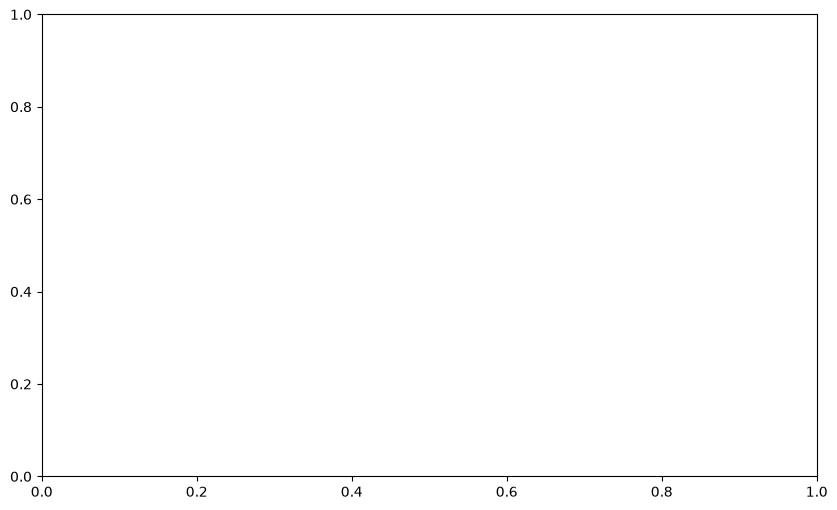

In [ ]:
# Import Matplotlib for data visualization.

import matplotlib.pyplot as plt

# Create a bar chart showing net item sales by order status.

sales_by_status["net_sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Net Item Sales by Order Status",
    xlabel="Net Item Sales",
    ylabel="Order Status"
)

# Adjust spacing and display the chart.

plt.tight_layout()
plt.show()

In [ ]:
# Check the data types of the sales metrics.
# Matplotlib requires numeric values to generate the bar chart.

print("Sales column data types:")
print(sales_by_status[["gross_sales", "net_sales"]].dtypes)

# Display the sales values to inspect their current format.

print("\nSales data:")
print(sales_by_status[["gross_sales", "net_sales"]])

Sales column data types:
gross_sales    object
net_sales      object
dtype: object

Sales data:
           gross_sales   net_sales
status                            
delivered   6571831.87  6511492.11
shipped     1019761.30  1010538.43
cancelled    549445.66   544649.08
processing   528512.86   523440.75
returned     438236.89   433939.39


In [ ]:
# Convert the sales columns into numeric data types.
# errors="raise" ensures that unexpected non-numeric values
# are reported instead of silently converted.

sales_by_status["gross_sales"] = pd.to_numeric(
    sales_by_status["gross_sales"],
    errors="raise"
)

sales_by_status["net_sales"] = pd.to_numeric(
    sales_by_status["net_sales"],
    errors="raise"
)

# Verify the corrected data types.

print("Updated data types:")
print(sales_by_status[["gross_sales", "net_sales"]].dtypes)

Updated data types:
gross_sales    float64
net_sales      float64
dtype: object


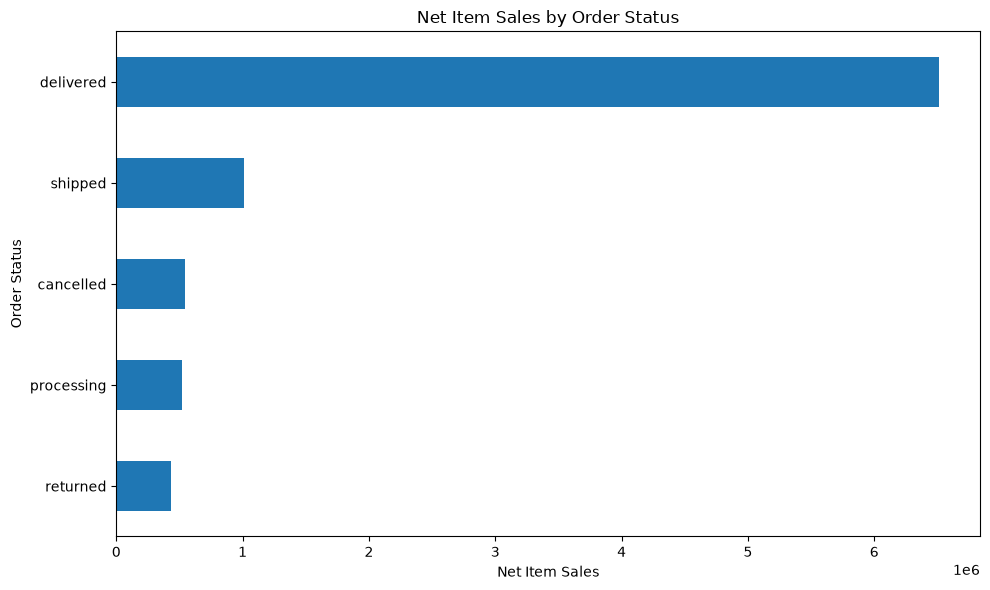

In [ ]:
# Visualize net item sales across different order statuses.
# Sorting makes it easier to compare the categories.

sales_by_status["net_sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Net Item Sales by Order Status",
    xlabel="Net Item Sales",
    ylabel="Order Status"
)

# Adjust chart spacing and display the visualization.

plt.tight_layout()
plt.show()

In [ ]:
# Display sales performance by order status in descending order.
# This helps identify which order statuses contribute the most sales.

print("Sales Performance by Order Status:")
display(sales_by_status.round(2))

# Display the percentage contribution of each status to net item sales.

print("\nNet Sales Contribution (%):")
print(sales_by_status["sales_percentage"].round(2))

Sales Performance by Order Status:


,total_orders,gross_sales,net_sales,sales_percentage
status,,,,
delivered,63978,6571831.87,6511492.11,72.15701450540925939080882151
shipped,9813,1019761.30,1010538.43,11.19826837228303106893432186
cancelled,5347,549445.66,544649.08,6.035521644196203771593817548
processing,5276,528512.86,523440.75,5.800501813166184085642624335
returned,4344,438236.89,433939.39,4.808693664945321683020414750



Net Sales Contribution (%):
status
delivered     72.16
shipped       11.20
cancelled      6.04
processing     5.80
returned       4.81
Name: sales_percentage, dtype: object


### Check 3: Order Volume and Average Net Item Value

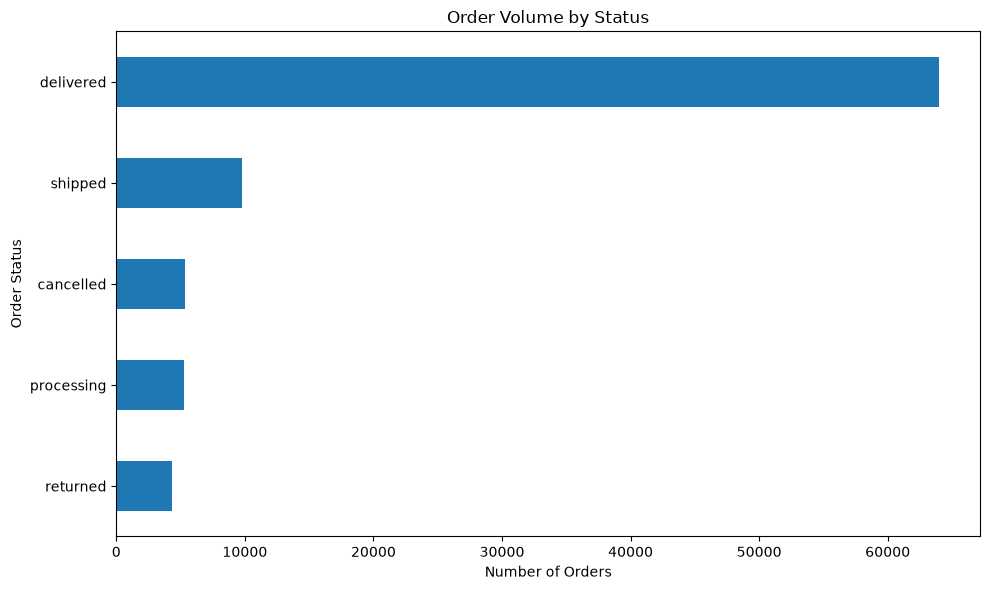

In [ ]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Step 1 – Overall Sales Performance
# Check 3: Order Volume by Status

# Create a bar chart showing the number of orders in each status.
# This helps compare the volume of orders across different statuses.

sales_by_status["total_orders"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Order Volume by Status",
    xlabel="Number of Orders",
    ylabel="Order Status"
)

# Adjust the chart layout and display the visualization.

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the average net item value per order for each status.
# Divide total net item sales by the number of unique orders.
# This helps compare the average order value across statuses.

sales_by_status["average_order_value"] = (
    sales_by_status["net_sales"] /
    sales_by_status["total_orders"]
)

print("Average Net Item Value per Order:")

print(
    sales_by_status["average_order_value"].round(2)
    .sort_values(ascending=False)
)

Average Net Item Value per Order:
status
shipped       102.98
cancelled     101.86
delivered     101.78
returned       99.89
processing     99.21
Name: average_order_value, dtype: float64


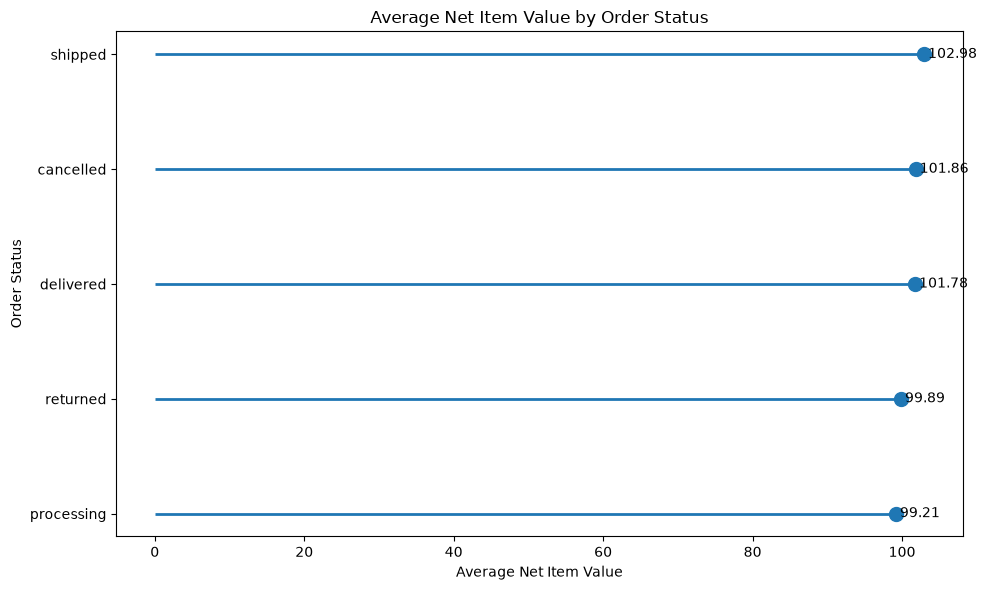

In [ ]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Step 1 – Overall Sales Performance
# Check 3: Average Net Item Value by Order Status
# Visualization: Lollipop Chart

import matplotlib.pyplot as plt

# Sort order statuses by their average net item value.

plot_data = sales_by_status["average_order_value"].sort_values()

# Create the chart canvas.

fig, ax = plt.subplots(figsize=(10, 6))

# Draw horizontal lines from zero to each average value.

ax.hlines(
    y=plot_data.index,
    xmin=0,
    xmax=plot_data.values,
    linewidth=2
)

# Add circular markers at the end of each line.

ax.scatter(
    plot_data.values,
    plot_data.index,
    s=100
)

# Add numerical labels beside each marker.

for position, value in enumerate(plot_data.values):
    ax.text(value + 0.5, position, f"{value:.2f}", va="center")

# Add chart title and axis labels.

ax.set_title("Average Net Item Value by Order Status")
ax.set_xlabel("Average Net Item Value")
ax.set_ylabel("Order Status")

# Display the chart.

plt.tight_layout()
plt.show()

In [20]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Recovery: Restore datasets after kernel restart

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load all original Parquet files from the Dataset folder.

DATA_DIR = Path("../Dataset")

tables = {
    file.stem: pd.read_parquet(file)
    for file in DATA_DIR.glob("*.parquet")
}

# Create independent working copies for analysis.

clean_tables = {
    name: df.copy()
    for name, df in tables.items()
}

# Restore the data type conversions completed in Phase 2.

clean_tables["categories"]["parent_category_id"] = (
    clean_tables["categories"]["parent_category_id"].astype("Int32")
)

clean_tables["customers"]["signup_date"] = pd.to_datetime(
    clean_tables["customers"]["signup_date"]
)

clean_tables["products"]["discontinued_at"] = pd.to_datetime(
    clean_tables["products"]["discontinued_at"]
)

# Recreate the Phase 3 sales dataset.

sales_data = clean_tables["order_items"].copy()

# Calculate gross item value before discounts.

sales_data["gross_item_value"] = (
    sales_data["quantity"] * sales_data["unit_price"]
)

# Calculate net item value after discounts.

sales_data["net_item_value"] = (
    sales_data["gross_item_value"] - sales_data["discount_amount"]
)

print("Datasets and sales variables restored successfully!")

Datasets and sales variables restored successfully!


## Step 2 – Sales Trends and Seasonality

### Check 1: Monthly Sales Trend

In [21]:
# Phase 3 – Exploratory Data Analysis (EDA)
# Step 2 – Sales Trends and Seasonality
# Check 1: Monthly Sales Trend

# Create a copy of the order items and order dates.
# This allows us to analyse sales over time without modifying clean_tables.

monthly_sales_data = sales_data.merge(
    clean_tables["orders"][["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

# Convert order dates into datetime format.
# This ensures Pandas can correctly group records by month.

monthly_sales_data["ordered_at"] = pd.to_datetime(
    monthly_sales_data["ordered_at"]
)

# Group sales by month and calculate total net item sales.

monthly_sales = (
    monthly_sales_data
    .set_index("ordered_at")
    .resample("ME")["net_item_value"]
    .sum()
)

# Display the first 12 months of sales.

print("Monthly Net Item Sales:")
print(monthly_sales.head(12).round(2))

Monthly Net Item Sales:
ordered_at
2023-01-31    249383.94
2023-02-28    196808.10
2023-03-31    230940.75
2023-04-30    216770.47
2023-05-31    230545.61
2023-06-30    210060.75
2023-07-31    227607.62
2023-08-31    228119.55
2023-09-30    203881.74
2023-10-31    226889.41
2023-11-30    347667.75
2023-12-31    390875.92
Freq: ME, Name: net_item_value, dtype: object


In [22]:
# Calculate descriptive statistics for monthly sales.
# This helps us understand the typical monthly sales value
# and the variation between months.

print("Monthly Sales Summary:")
print(monthly_sales.describe().round(2))

# Identify the highest and lowest sales months.

print("\nHighest Sales Month:")
print(monthly_sales.idxmax(), round(monthly_sales.max(), 2))

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), round(monthly_sales.min(), 2))

Monthly Sales Summary:
count            36
unique           36
top       249383.94
freq              1
Name: net_item_value, dtype: object

Highest Sales Month:
2024-12-31 00:00:00 425370.88

Lowest Sales Month:
2023-02-28 00:00:00 196808.10


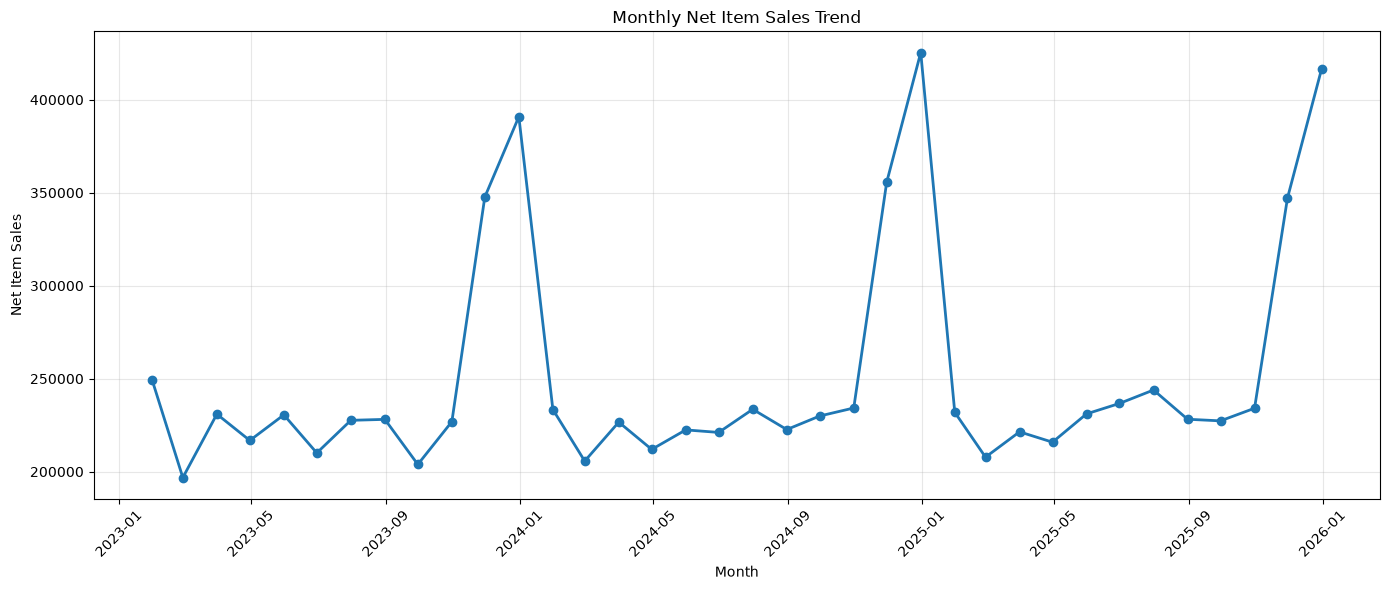

In [23]:
# Visualize monthly net item sales using a line chart.
# This helps identify trends, fluctuations and potential seasonality.

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

# Add chart title and axis labels.

plt.title("Monthly Net Item Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Item Sales")

# Rotate date labels for better readability.

plt.xticks(rotation=45)

# Add a grid to make monthly comparisons easier.

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Check 2: Annual Sales and Year-over-Year Growth

In [24]:
# Convert monthly sales values to numeric so calculations work correctly
monthly_sales = pd.to_numeric(monthly_sales, errors="raise")

# Calculate total net item sales for each year
yearly_sales = monthly_sales.resample("YE").sum()

# Display yearly sales totals
print("Yearly Net Item Sales:")
print(yearly_sales.round(2))

Yearly Net Item Sales:
ordered_at
2023-12-31    2959551.61
2024-12-31    3022636.02
2025-12-31    3041872.13
Freq: YE-DEC, Name: net_item_value, dtype: float64


In [25]:
# Calculate the percentage change in sales compared with the previous year
yearly_growth = yearly_sales.pct_change() * 100

# Display the year-over-year growth rate
print("Year-over-Year Sales Growth (%):")
print(yearly_growth.round(2))

Year-over-Year Sales Growth (%):
ordered_at
2023-12-31     NaN
2024-12-31    2.13
2025-12-31    0.64
Freq: YE-DEC, Name: net_item_value, dtype: float64


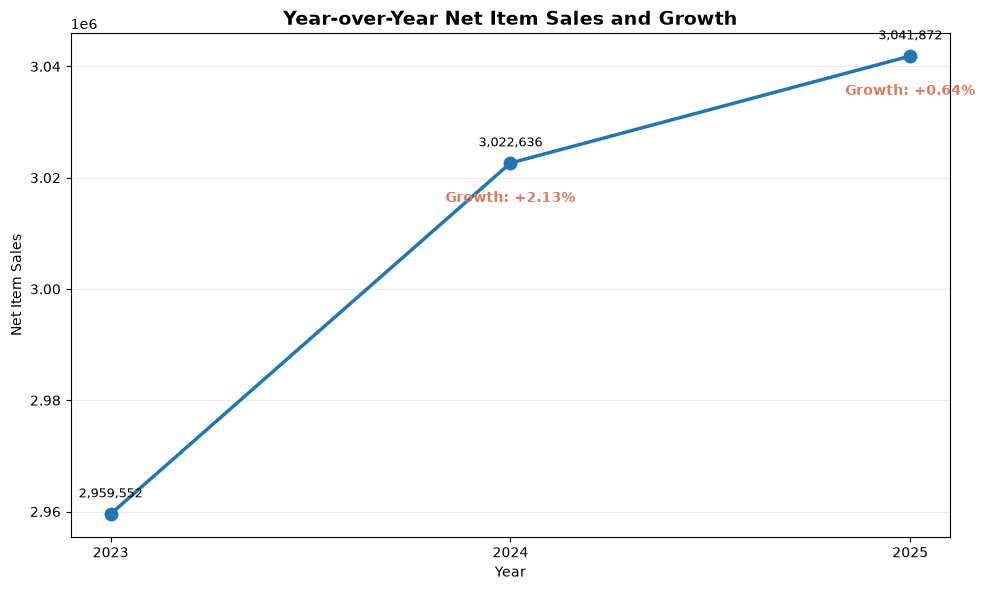

In [34]:
# Create a line chart showing yearly net item sales
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_sales.index.year,
    yearly_sales.values,
    marker="o",
    linewidth=2.5,
    markersize=9
)

# Add yearly sales values above each data point
for year, value in zip(yearly_sales.index.year, yearly_sales.values):
    plt.annotate(
        f"{value:,.0f}",
        (year, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

# Add year-over-year growth percentages between the years
for i in range(1, len(yearly_growth)):
    year = yearly_growth.index.year[i]
    growth = yearly_growth.iloc[i]

    plt.annotate(
        f"Growth: +{growth:.2f}%",
        xy=(year, yearly_sales.iloc[i]),
        xytext=(0, -28),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#E07A5F"
    )

# Add chart title and axis labels
plt.title("Year-over-Year Net Item Sales and Growth", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Net Item Sales")

plt.xticks(yearly_sales.index.year)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Check 3: Calendar-Month Seasonality and Extreme Months

In [27]:
# Group monthly sales by calendar month (January to December)
# Calculate the average sales for each month across all three years
average_monthly_sales = monthly_sales.groupby(
    monthly_sales.index.month
).mean()

# Give each month its readable name
average_monthly_sales.index = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Display the average monthly sales
print("Average Net Item Sales by Calendar Month:")
print(average_monthly_sales.round(2))

Average Net Item Sales by Calendar Month:
January      238241.10
February     203430.99
March        226330.32
April        214863.50
May          228025.84
June         222616.71
July         235020.97
August       226316.78
September    220375.67
October      231743.81
November     350162.04
December     410892.19
Name: net_item_value, dtype: float64


In [28]:
# Find the calendar month with the highest average sales
highest_month = average_monthly_sales.idxmax()
highest_value = average_monthly_sales.max()

# Find the calendar month with the lowest average sales
lowest_month = average_monthly_sales.idxmin()
lowest_value = average_monthly_sales.min()

# Display the results
print("Highest Average Sales Month:", highest_month, "-", round(highest_value, 2))
print("Lowest Average Sales Month:", lowest_month, "-", round(lowest_value, 2))

Highest Average Sales Month: December - 410892.19
Lowest Average Sales Month: February - 203430.99


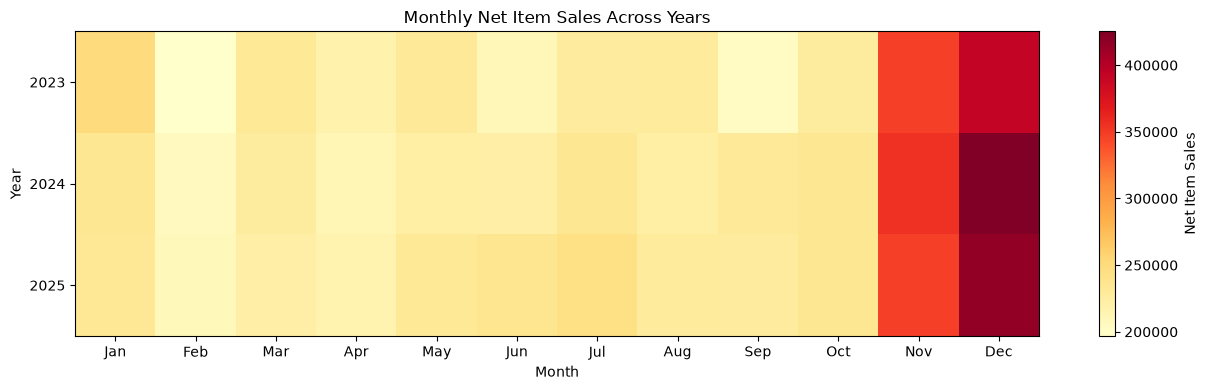

In [30]:
# Convert monthly sales into a table with years as rows and months as columns
seasonal_heatmap = monthly_sales.to_frame().copy()

seasonal_heatmap["Year"] = seasonal_heatmap.index.year
seasonal_heatmap["Month"] = seasonal_heatmap.index.month

seasonal_heatmap = seasonal_heatmap.pivot(
    index="Year",
    columns="Month",
    values="net_item_value"
)

# Replace month numbers with readable names
seasonal_heatmap.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create a heatmap to compare monthly sales across years
plt.figure(figsize=(13, 4))

plt.imshow(seasonal_heatmap, aspect="auto", cmap="YlOrRd")

# Add month and year labels
plt.xticks(range(12), seasonal_heatmap.columns)
plt.yticks(range(len(seasonal_heatmap.index)), seasonal_heatmap.index)

# Add a color scale
plt.colorbar(label="Net Item Sales")

# Add chart title
plt.title("Monthly Net Item Sales Across Years")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

In [31]:
# Sort all 36 months by net item sales
# Identify the five months with the highest sales
top_5_months = monthly_sales.sort_values(ascending=False).head(5)

# Identify the five months with the lowest sales
bottom_5_months = monthly_sales.sort_values(ascending=True).head(5)

# Display the results
print("Top 5 Highest Sales Months:")
print(top_5_months.round(2))

print("\nTop 5 Lowest Sales Months:")
print(bottom_5_months.round(2))

Top 5 Highest Sales Months:
ordered_at
2024-12-31    425370.88
2025-12-31    416429.76
2023-12-31    390875.92
2024-11-30    355650.81
2023-11-30    347667.75
Name: net_item_value, dtype: float64

Top 5 Lowest Sales Months:
ordered_at
2023-02-28    196808.10
2023-09-30    203881.74
2024-02-29    205686.50
2025-02-28    207798.37
2023-06-30    210060.75
Name: net_item_value, dtype: float64


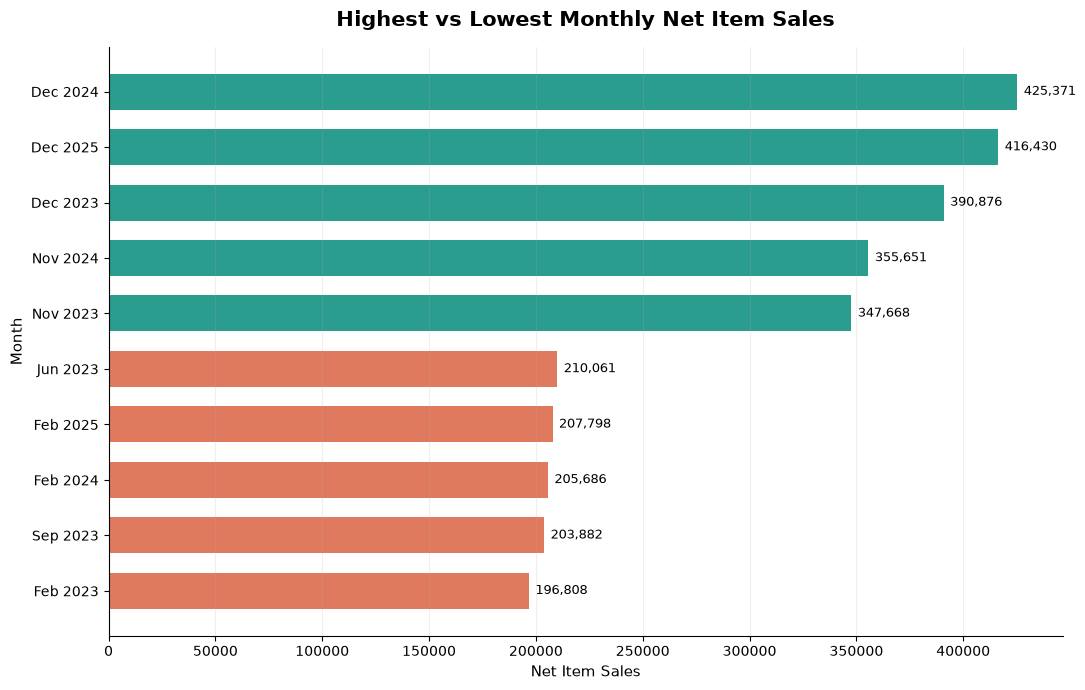

In [33]:
# Combine the five highest and five lowest sales months
extreme_months = pd.concat([
    top_5_months,
    bottom_5_months
]).sort_values()

# Create readable month-year labels
month_labels = extreme_months.index.strftime("%b %Y")

# Assign colours: coral for the lowest months, teal for the highest
bar_colors = [
    "#E07A5F" if date in bottom_5_months.index else "#2A9D8F"
    for date in extreme_months.index
]

# Create the horizontal comparison chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    month_labels,
    extreme_months.values,
    color=bar_colors,
    height=0.65
)

# Add chart title and axis labels
plt.title(
    "Highest vs Lowest Monthly Net Item Sales",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Net Item Sales", fontsize=11)
plt.ylabel("Month", fontsize=11)

# Display values at the end of each bar
for bar, value in zip(bars, extreme_months.values):
    plt.text(
        value + 3000,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=9
    )

# Remove unnecessary borders for a cleaner appearance
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 3 – Customer Behaviour Analysis

### Check 1: Customer Purchasing Frequency

In [35]:
#step 3: customer behaviour ananlysis
# Count how many orders each customer has placed
# Group the orders table by customer_id and count unique order IDs
customer_order_frequency = (
    clean_tables["orders"]
    .groupby("customer_id")["order_id"]
    .nunique()
)

# Display the basic customer purchasing statistics
print("Customer Purchasing Frequency Summary")
print("--------------------------------------")

print("Total customers with orders:", len(customer_order_frequency))
print("Average orders per customer:", round(customer_order_frequency.mean(), 2))
print("Median orders per customer:", customer_order_frequency.median())
print("Minimum orders:", customer_order_frequency.min())
print("Maximum orders:", customer_order_frequency.max())

Customer Purchasing Frequency Summary
--------------------------------------
Total customers with orders: 8622
Average orders per customer: 10.44
Median orders per customer: 2.0
Minimum orders: 1
Maximum orders: 11175


In [36]:
# Generate descriptive statistics to understand the distribution
print("Customer Order Frequency Distribution:")
print(customer_order_frequency.describe().round(2))

# Count customers according to their number of orders
print("\nNumber of Customers by Order Frequency:")
print(customer_order_frequency.value_counts().sort_index().head(15))

Customer Order Frequency Distribution:
count     8622.00
mean        10.44
std        150.02
min          1.00
25%          1.00
50%          2.00
75%          4.00
max      11175.00
Name: order_id, dtype: float64

Number of Customers by Order Frequency:
order_id
1     3246
2     1921
3      997
4      565
5      368
6      221
7      175
8      141
9       98
10      83
11      77
12      69
13      52
14      44
15      30
Name: count, dtype: int64


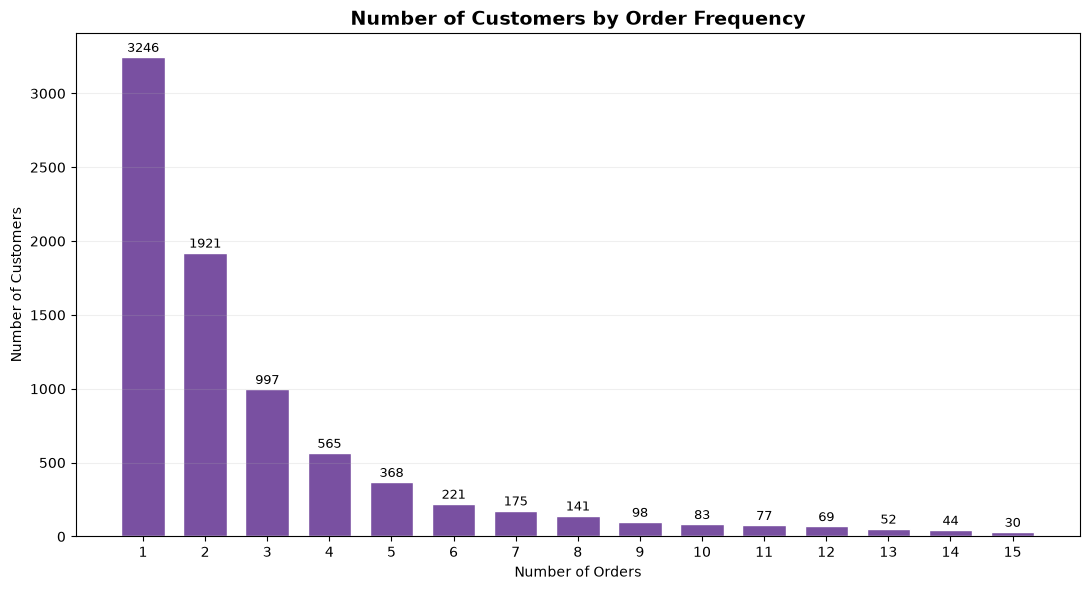

In [39]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 1: Customer Purchasing Frequency
# Visualization: Most Common Customer Order Frequencies

# Select the 15 most common order frequencies
frequency_counts = customer_order_frequency.value_counts().sort_index().head(15)

# Create the chart
plt.figure(figsize=(11, 6))

plt.bar(
    frequency_counts.index.astype(str),
    frequency_counts.values,
    color="#7950A1",
    edgecolor="white",
    width=0.7
)

# Add title and axis labels
plt.title("Number of Customers by Order Frequency",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

# Display values above the bars
for position, value in enumerate(frequency_counts.values):
    plt.text(position, value + 35, str(value), ha="center", fontsize=9)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Check 2: Customer Spending Patterns

In [40]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 2: Customer Spending Patterns
# Calculate total net item sales for each customer

# Merge order items with orders to identify which customer placed each order
customer_spending_data = sales_data.merge(
    clean_tables["orders"][["order_id", "customer_id"]],
    on="order_id",
    how="inner"
)

# Calculate total net item sales for each customer
customer_spending = customer_spending_data.groupby(
    "customer_id"
)["net_item_value"].sum()

# Display customer spending statistics
print("Customer Spending Summary")
print("--------------------------")
print("Total customers:", len(customer_spending))
print("Total net item sales:", round(customer_spending.sum(), 2))
print("Average customer spending:", round(customer_spending.mean(), 2))
print("Median customer spending:", round(customer_spending.median(), 2))
print("Highest customer spending:", round(customer_spending.max(), 2))
print("Lowest customer spending:", round(customer_spending.min(), 2))

Customer Spending Summary
--------------------------
Total customers: 8567
Total net item sales: 9024059.76
Average customer spending: 1053.35
Median customer spending: 199.46
Highest customer spending: 1131634.25
Lowest customer spending: 3.80


In [41]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 2: Customer Spending Patterns
# Examine the distribution of customer spending

# Generate descriptive statistics for customer spending
print("Customer Spending Distribution:")
print(customer_spending.describe().round(2))

# Identify the five customers with the highest total spending
print("\nTop 5 Highest-Spending Customers:")
print(customer_spending.sort_values(ascending=False).head(5).round(2))

# Identify the five customers with the lowest total spending
print("\nTop 5 Lowest-Spending Customers:")
print(customer_spending.sort_values().head(5).round(2))

Customer Spending Distribution:
count      8567
unique     7578
top       13.55
freq         99
Name: net_item_value, dtype: object

Top 5 Highest-Spending Customers:
customer_id
1    1131634.25
2     550729.71
3     347538.18
4     254836.66
5     205380.78
Name: net_item_value, dtype: object

Top 5 Lowest-Spending Customers:
customer_id
11672    3.80
6677     4.06
4064     5.20
3531     6.10
6901     6.30
Name: net_item_value, dtype: object


In [42]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 2: Customer Spending Patterns
# Prepare numeric customer spending values

# Convert customer spending values into numeric format
customer_spending = pd.to_numeric(
    customer_spending,
    errors="raise"
)

# Display corrected descriptive statistics
print("Updated Customer Spending Distribution:")
print(customer_spending.describe().round(2))

Updated Customer Spending Distribution:
count       8567.00
mean        1053.35
std        15166.84
min            3.80
25%           86.46
50%          199.46
75%          441.48
max      1131634.25
Name: net_item_value, dtype: float64


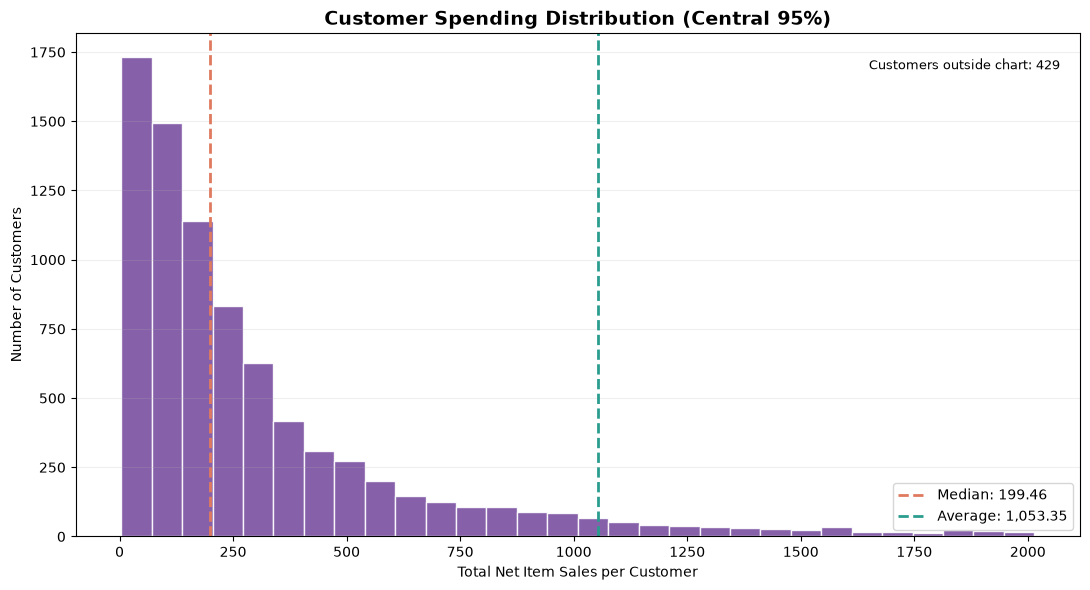

In [46]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 2: Customer Spending Patterns
# Visualization: Customer Spending Distribution (Central 95%)

# Calculate the 95th percentile to identify the upper display limit
upper_limit = customer_spending.quantile(0.95)

# Keep customers whose spending falls within the central 95%
spending_central = customer_spending[
    customer_spending <= upper_limit
]

# Count how many customers are outside the displayed range
excluded_customers = len(customer_spending) - len(spending_central)

# Create the histogram
plt.figure(figsize=(11, 6))

plt.hist(
    spending_central,
    bins=30,
    color="#7950A1",
    edgecolor="white",
    alpha=0.9
)

# Show the median and average spending for comparison
plt.axvline(
    customer_spending.median(),
    color="#E07A5F",
    linestyle="--",
    linewidth=2,
    label=f"Median: {customer_spending.median():,.2f}"
)

plt.axvline(
    customer_spending.mean(),
    color="#2A9D8F",
    linestyle="--",
    linewidth=2,
    label=f"Average: {customer_spending.mean():,.2f}"
)

# Add chart title and axis labels
plt.title(
    "Customer Spending Distribution (Central 95%)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Total Net Item Sales per Customer")
plt.ylabel("Number of Customers")

# Add legend and grid
plt.legend()
plt.grid(axis="y", alpha=0.2)

# Display how many customers are excluded from the chart
plt.text(
    0.98, 0.95,
    f"Customers outside chart: {excluded_customers}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=9
)

plt.tight_layout()
plt.show()

### Check 3: One-Time and Repeat Customers

In [47]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 3: New vs Repeat Customers
# Classify customers based on their total number of orders

# Count customers who placed exactly one order
one_time_customers = (customer_order_frequency == 1).sum()

# Count customers who placed more than one order
repeat_customers = (customer_order_frequency > 1).sum()

# Calculate the total number of customers who placed orders
total_active_customers = len(customer_order_frequency)

# Calculate the percentage of one-time and repeat customers
one_time_percentage = (one_time_customers / total_active_customers) * 100
repeat_percentage = (repeat_customers / total_active_customers) * 100

# Display the results
print("New vs Repeat Customer Summary")
print("--------------------------------")
print("Total customers:", total_active_customers)
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

print("\nCustomer Percentage:")
print("One-time customers:", round(one_time_percentage, 2), "%")
print("Repeat customers:", round(repeat_percentage, 2), "%")

New vs Repeat Customer Summary
--------------------------------
Total customers: 8622
One-time customers: 3246
Repeat customers: 5376

Customer Percentage:
One-time customers: 37.65 %
Repeat customers: 62.35 %


In [48]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 3: New vs Repeat Customers
# Create a summary table for customer classification

# Organize customer counts and percentages into a DataFrame
customer_type_summary = pd.DataFrame({
    "Customer Type": ["One-time Customers", "Repeat Customers"],
    "Customer Count": [one_time_customers, repeat_customers],
    "Percentage": [one_time_percentage, repeat_percentage]
})

# Display the customer comparison
print(customer_type_summary.round(2))

        Customer Type  Customer Count  Percentage
0  One-time Customers            3246       37.65
1    Repeat Customers            5376       62.35


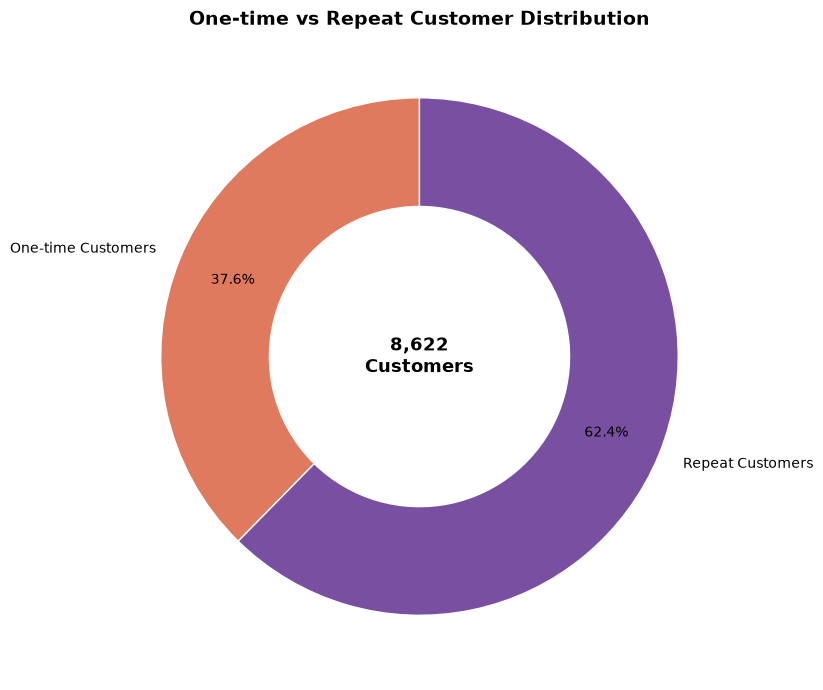

In [49]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 3: New vs Repeat Customers
# Visualization: One-time vs Repeat Customer Distribution

# Define customer categories and their counts
customer_labels = ["One-time Customers", "Repeat Customers"]
customer_counts = [one_time_customers, repeat_customers]

# Create the donut chart
plt.figure(figsize=(8, 7))

plt.pie(
    customer_counts,
    labels=customer_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E07A5F", "#7950A1"],
    wedgeprops=dict(width=0.42, edgecolor="white"),
    pctdistance=0.78
)

# Add total customer count in the centre
plt.text(
    0, 0,
    f"{total_active_customers:,}\nCustomers",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

# Add chart title
plt.title(
    "One-time vs Repeat Customer Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Check 4: Monthly Customer Activity

In [50]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 4: Customer Purchase Activity Over Time
# Prepare customer order dates for monthly analysis

# Select the required columns from the orders table
customer_activity = clean_tables["orders"][
    ["order_id", "customer_id", "ordered_at"]
].copy()

# Convert order dates into datetime format
customer_activity["ordered_at"] = pd.to_datetime(
    customer_activity["ordered_at"]
)

# Extract the month of each order
customer_activity["order_month"] = (
    customer_activity["ordered_at"].dt.to_period("M")
)

# Display the first few records
print("Customer Purchase Activity:")
print(customer_activity.head())

Customer Purchase Activity:
   order_id  customer_id          ordered_at order_month
0         1           21 2024-09-30 16:00:03     2024-09
1         2          181 2025-11-25 18:26:28     2025-11
2         3         5155 2025-12-02 20:36:03     2025-12
3         4         7717 2025-11-30 17:54:32     2025-11
4         5          494 2024-07-27 11:59:39     2024-07


In [51]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 4: Customer Purchase Activity Over Time
# Calculate the number of unique purchasing customers each month

# Count unique customers who placed orders in each month
monthly_active_customers = customer_activity.groupby(
    "order_month"
)["customer_id"].nunique()

# Display monthly active customer counts
print("Monthly Active Customers:")
print(monthly_active_customers)

# Display summary statistics
print("\nMonthly Active Customer Summary:")
print(monthly_active_customers.describe().round(2))

Monthly Active Customers:
order_month
2023-01     887
2023-02     795
2023-03     871
2023-04     868
2023-05     894
2023-06     859
2023-07     863
2023-08     872
2023-09     838
2023-10     887
2023-11    1275
2023-12    1366
2024-01     912
2024-02     802
2024-03     843
2024-04     838
2024-05     895
2024-06     885
2024-07     899
2024-08     876
2024-09     882
2024-10     925
2024-11    1211
2024-12    1377
2025-01     898
2025-02     807
2025-03     871
2025-04     869
2025-05     882
2025-06     863
2025-07     940
2025-08     871
2025-09     912
2025-10     861
2025-11    1234
2025-12    1372
Freq: M, Name: customer_id, dtype: int64

Monthly Active Customer Summary:
count      36.00
mean      944.44
std       169.12
min       795.00
25%       863.00
50%       882.00
75%       912.00
max      1377.00
Name: customer_id, dtype: float64


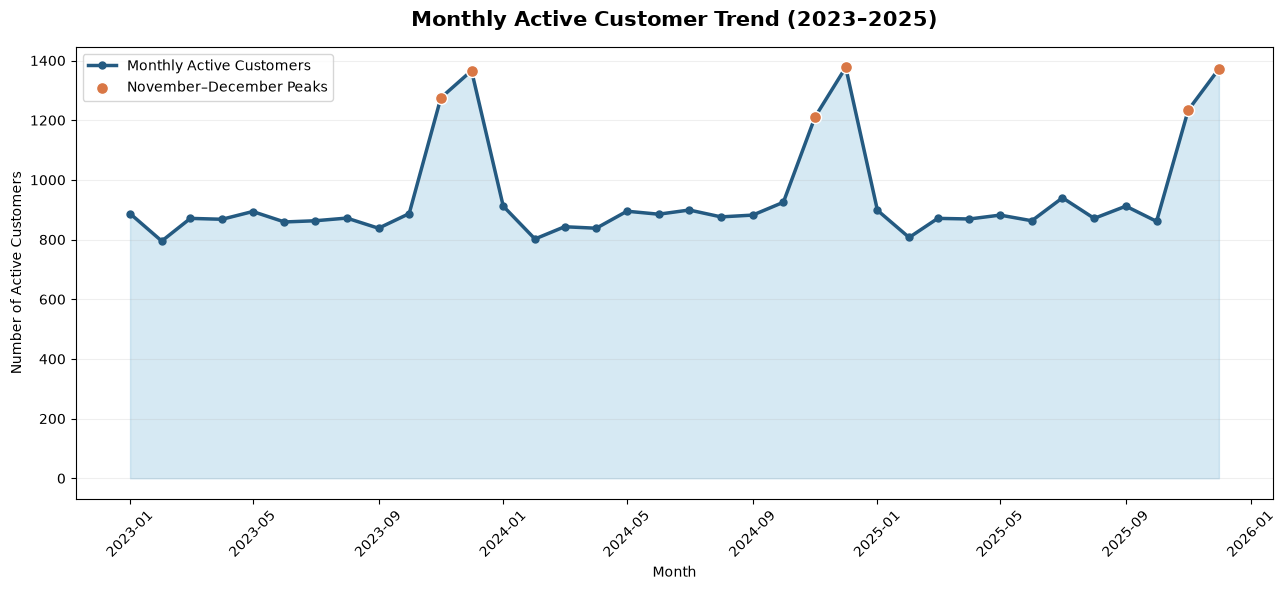

In [53]:
# Phase 3 – Step 3: Customer Behaviour Analysis
# Check 4: Customer Purchase Activity Over Time
# Visualization: Monthly Active Customers with Shaded Area

# Convert monthly periods into timestamps for plotting
monthly_customer_dates = monthly_active_customers.index.to_timestamp()

# Create the chart
plt.figure(figsize=(13, 6))

# Draw the line showing monthly active customers
plt.plot(
    monthly_customer_dates,
    monthly_active_customers.values,
    color="#245A81",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Monthly Active Customers"
)

# Fill the area below the line
plt.fill_between(
    monthly_customer_dates,
    monthly_active_customers.values,
    color="#79B8D8",
    alpha=0.30
)

# Highlight November and December activity
year_end_mask = monthly_customer_dates.month.isin([11, 12])

plt.scatter(
    monthly_customer_dates[year_end_mask],
    monthly_active_customers.values[year_end_mask],
    color="#D97745",
    edgecolor="white",
    linewidth=1,
    s=75,
    zorder=3,
    label="November–December Peaks"
)

# Add chart title and axis labels
plt.title(
    "Monthly Active Customer Trend (2023–2025)",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Month")
plt.ylabel("Number of Active Customers")

# Format the x-axis
plt.xticks(rotation=45)

# Add legend and grid
plt.legend()
plt.grid(axis="y", alpha=0.2)

# Improve spacing
plt.tight_layout()
plt.show()

## Step 4 – Customer Segmentation and Purchasing Patterns

### Check 1: Customer Value Segmentation

In [54]:
# Phase 3 – Step 4: Customer Segmentation and Purchasing Patterns
# Check 1: Customer Value Segmentation
# Divide customers into Low, Medium and High spending groups

# Calculate the 33rd and 67th spending percentiles
low_threshold = customer_spending.quantile(0.33)
high_threshold = customer_spending.quantile(0.67)

# Assign each customer to a spending segment
customer_segments = pd.cut(
    customer_spending,
    bins=[-float("inf"), low_threshold, high_threshold, float("inf")],
    labels=["Low Value", "Medium Value", "High Value"],
    include_lowest=True
)

# Combine customer spending and segment information
customer_segment_data = pd.DataFrame({
    "Total Spending": customer_spending,
    "Customer Segment": customer_segments
})

# Summarize the number of customers in each segment
print("Customer Segmentation Summary:")
print(customer_segment_data["Customer Segment"].value_counts().sort_index())

Customer Segmentation Summary:
Customer Segment
Low Value       2827
Medium Value    2913
High Value      2827
Name: count, dtype: int64


In [55]:
# Phase 3 – Step 4: Customer Segmentation and Purchasing Patterns
# Check 1: Customer Value Segmentation
# Compare customer count and spending contribution across segments

# Calculate customer count, average spending and total spending per segment
segment_summary = customer_segment_data.groupby(
    "Customer Segment",
    observed=False
)["Total Spending"].agg(
    Customer_Count="count",
    Average_Spending="mean",
    Total_Spending="sum"
)

# Calculate each segment's contribution to total net item sales
segment_summary["Sales_Contribution_%"] = (
    segment_summary["Total_Spending"] /
    customer_spending.sum() * 100
)

# Display the segment comparison
print(segment_summary.round(2))

                  Customer_Count  Average_Spending  Total_Spending  \
Customer Segment                                                     
Low Value                   2827             59.31       167675.96   
Medium Value                2913            207.14       603390.54   
High Value                  2827           2919.35      8252993.26   

                  Sales_Contribution_%  
Customer Segment                        
Low Value                         1.86  
Medium Value                      6.69  
High Value                       91.46  


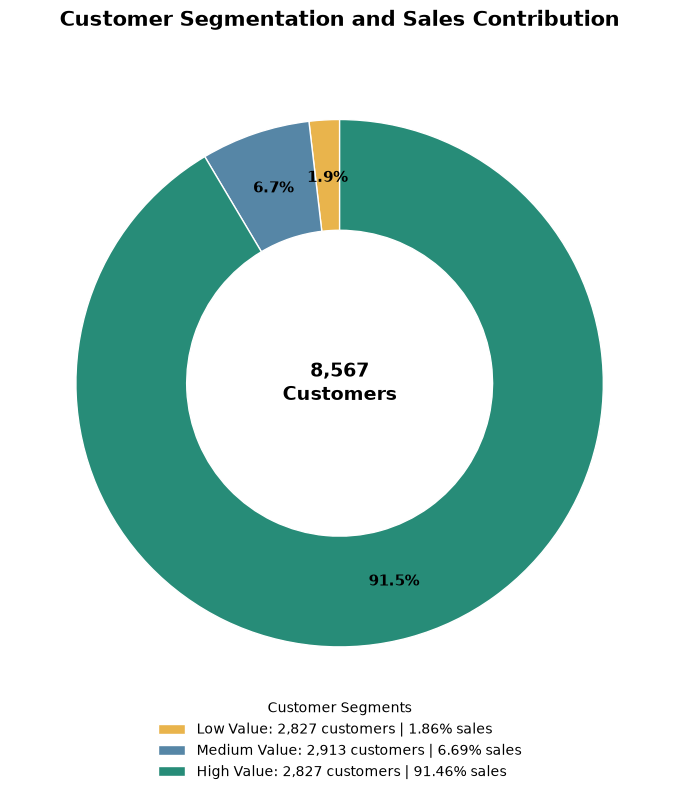

In [57]:
# Phase 3 – Step 4: Customer Segmentation and Purchasing Patterns
# Check 1: Customer Value Segmentation
# Visualization: Customer Count and Sales Contribution by Segment

# Extract customer counts and sales contribution
segment_labels = segment_summary.index.astype(str)
segment_counts = segment_summary["Customer_Count"]
segment_values = segment_summary["Sales_Contribution_%"]

# Define professional colours for the three segments
segment_colors = ["#E9B44C", "#5686A6", "#278C78"]

# Create a donut chart
fig, ax = plt.subplots(figsize=(10, 8))

wedges, _, _ = ax.pie(
    segment_values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    colors=segment_colors,
    pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    textprops={"fontsize": 11, "fontweight": "bold"}
)

# Add total customer count in the centre
ax.text(
    0, 0,
    f"{segment_counts.sum():,}\nCustomers",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

# Add segment names, customer counts and contribution to the legend
legend_labels = [
    f"{name}: {count:,} customers | {value:.2f}% sales"
    for name, count, value in zip(
        segment_labels, segment_counts, segment_values
    )
]

ax.legend(
    wedges,
    legend_labels,
    title="Customer Segments",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

ax.set_title(
    "Customer Segmentation and Sales Contribution",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

### Check 2: Purchasing Frequency by Segment

Purchasing Frequency by Customer Segment:
                  Customer_Count  Average_Orders  Median_Orders  Total_Orders
Customer Segment                                                             
Low Value                   2827            1.26            1.0          3555
Medium Value                2913            2.14            2.0          6245
High Value                  2827           28.35            6.0         80145


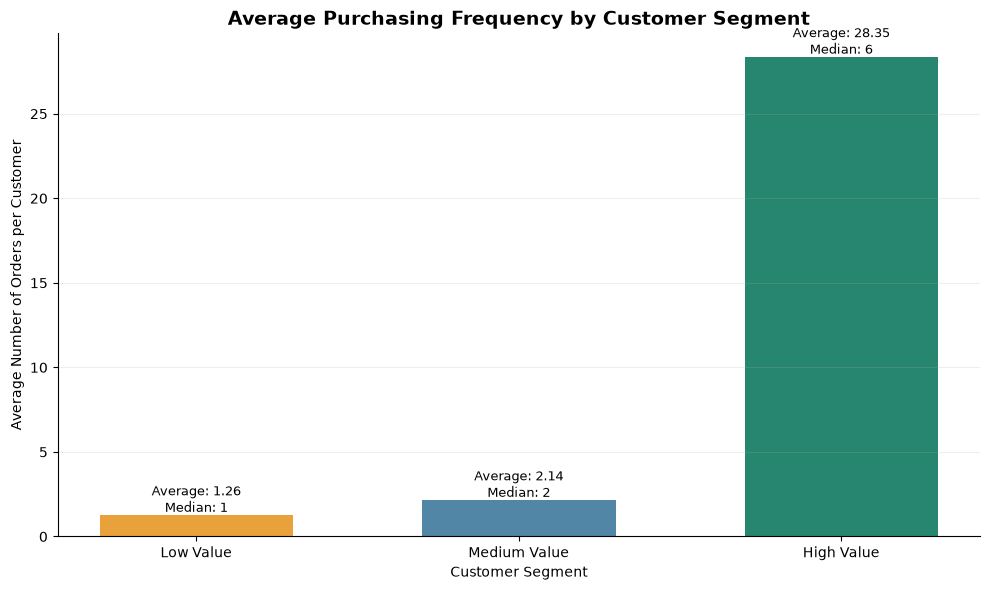

In [58]:
# Phase 3 – Step 4: Customer Segmentation and Purchasing Patterns
# Check 2: Purchasing Frequency by Customer Segment
# Compare order frequency across Low, Medium and High Value customers

# Combine customer segments with their order frequencies
customer_frequency_segments = pd.DataFrame({
    "Customer Segment": customer_segments,
    "Order Frequency": customer_order_frequency
})

# Calculate customer count, average orders and median orders per segment
frequency_segment_summary = customer_frequency_segments.groupby(
    "Customer Segment",
    observed=False
)["Order Frequency"].agg(
    Customer_Count="count",
    Average_Orders="mean",
    Median_Orders="median",
    Total_Orders="sum"
)

# Display the comparison
print("Purchasing Frequency by Customer Segment:")
print(frequency_segment_summary.round(2))

# Create a chart comparing average orders per customer
plt.figure(figsize=(10, 6))

bars = plt.bar(
    frequency_segment_summary.index.astype(str),
    frequency_segment_summary["Average_Orders"],
    color=["#E9A23B", "#5286A6", "#27866F"],
    width=0.6
)

# Display average and median orders on each bar
for bar, avg, median in zip(
    bars,
    frequency_segment_summary["Average_Orders"],
    frequency_segment_summary["Median_Orders"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"Average: {avg:.2f}\nMedian: {median:.0f}",
        ha="center",
        fontsize=9
    )

# Add chart details
plt.title(
    "Average Purchasing Frequency by Customer Segment",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Orders per Customer")

plt.grid(axis="y", alpha=0.2)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Step 5 – Product and Category Performance

### Check 1: Sales by Product Category

Sales Performance by Product Category:
               Total_Net_Sales  Total_Quantity  Products  \
category_name                                              
Fertiliser          1535067.56           82123        85   
Bulbs               1196606.19           44083        90   
Hoses                766107.46           18634        85   
Fire Pits            725974.87           20209        85   
Bagged Soil          689400.69           24007        97   
Garden Tools         616088.14           34346       102   
Outdoor Living       344134.05           10505        73   
Hand Tools           301955.33           11370        82   
Irrigation           280339.78           10004        75   
Mulch                254794.49           10581        68   
Festoon              245125.84            7977        77   
Sprinklers           212992.33            5581        77   
Furniture            209739.52            6406        90   
Solar                198121.12            8468        85   
P

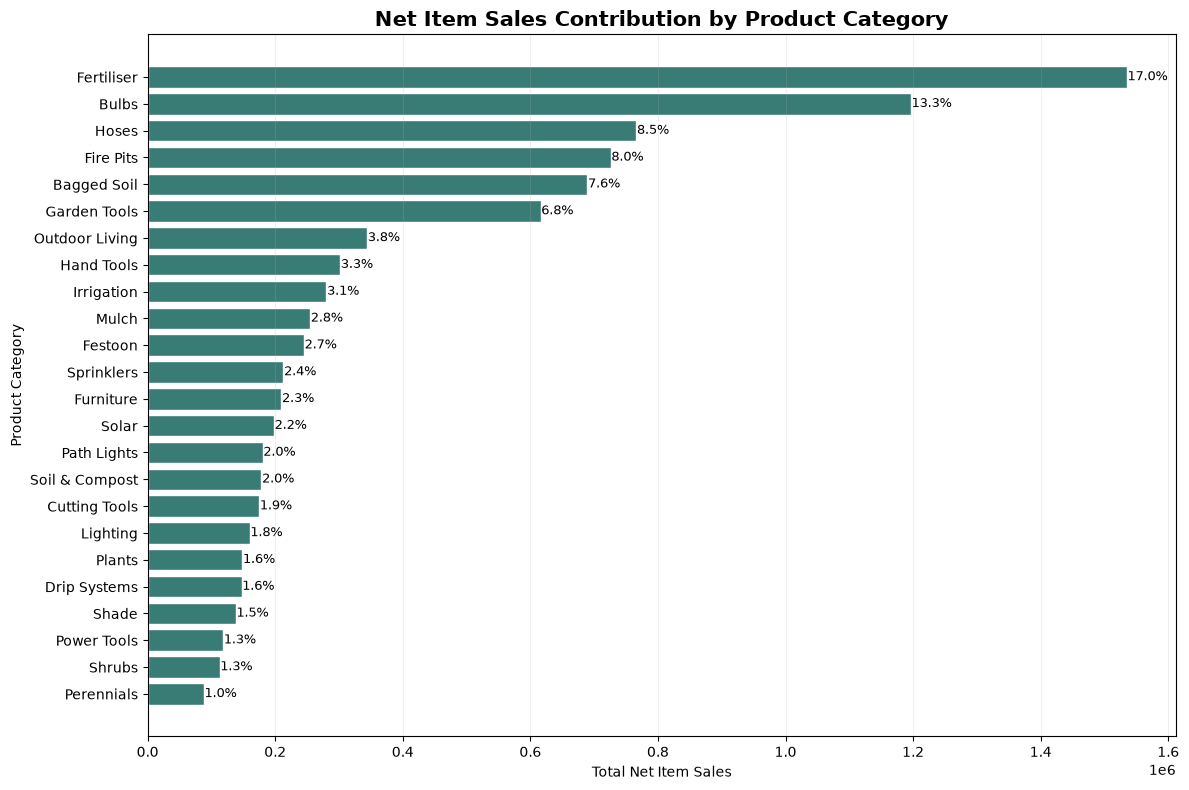

In [59]:
# Phase 3 – Step 5: Product and Category Performance
# Check 1: Sales Performance by Product Category
# Calculate category sales and visualize their contribution

# Merge item-level sales with product information
category_sales_data = sales_data.merge(
    clean_tables["products"][["product_id", "category_id"]],
    on="product_id",
    how="left"
)

# Merge category names into the sales data
category_sales_data = category_sales_data.merge(
    clean_tables["categories"][["category_id", "category_name"]],
    on="category_id",
    how="left"
)

# Calculate total sales and quantity for each category
category_sales_summary = category_sales_data.groupby(
    "category_name"
).agg(
    Total_Net_Sales=("net_item_value", "sum"),
    Total_Quantity=("quantity", "sum"),
    Products=("product_id", "nunique")
).sort_values(
    "Total_Net_Sales",
    ascending=False
)

# Calculate percentage contribution to total net item sales
category_sales_summary["Sales_Contribution_%"] = (
    category_sales_summary["Total_Net_Sales"] /
    category_sales_summary["Total_Net_Sales"].sum() * 100
)

# Display category performance
print("Sales Performance by Product Category:")
print(category_sales_summary.round(2))

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))

category_plot = category_sales_summary.sort_values("Total_Net_Sales")

bars = plt.barh(
    category_plot.index,
    category_plot["Total_Net_Sales"],
    color="#397B75",
    edgecolor="white"
)

# Display sales contribution percentage on each bar
for bar, percentage in zip(
    bars,
    category_plot["Sales_Contribution_%"]
):
    plt.text(
        bar.get_width() + 1000,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center",
        fontsize=9
    )

# Add chart title, axis labels and grid
plt.title(
    "Net Item Sales Contribution by Product Category",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Total Net Item Sales")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Check 2: Product-Level Sales Performance

Top 10 Products by Net Item Sales:
           Total_Net_Sales  Total_Quantity  Total_Orders
product_id                                              
1                915088.03           68492         34049
2                786428.54           31407         17194
4                621392.76           13649          7976
7                388356.33            7626          4505
3                239131.07           19377         11189
6                213247.81            8906          5336
5                198945.81           10689          6253
9                164224.44            5426          3256
8                161935.68            6401          3816
20               142352.21            2388          1412


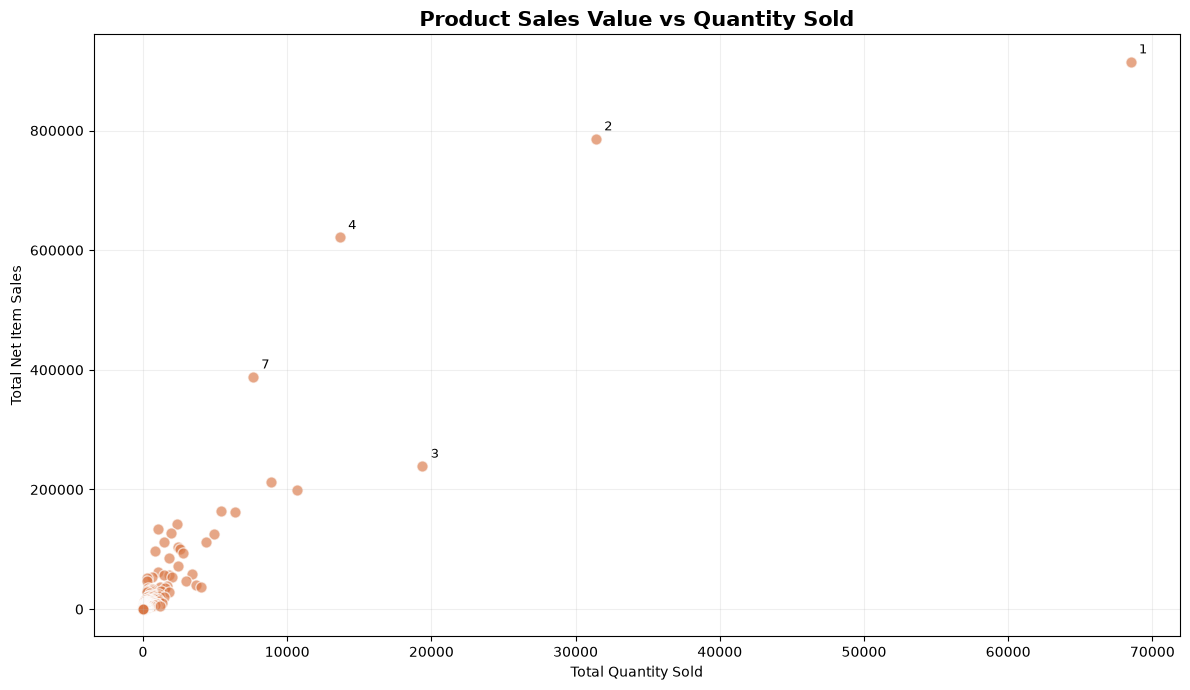

In [60]:
# Phase 3 – Step 5: Product and Category Performance
# Check 2: Product-Level Sales Performance
# Aggregate sales and quantity for each product, then compare them visually.

# Calculate total net sales and quantity sold for every product
product_sales_summary = sales_data.groupby("product_id").agg(
    Total_Net_Sales=("net_item_value", "sum"),
    Total_Quantity=("quantity", "sum"),
    Total_Orders=("order_id", "nunique")
).sort_values("Total_Net_Sales", ascending=False)

# Display the 10 products generating the highest net item sales
top_products = product_sales_summary.head(10)

print("Top 10 Products by Net Item Sales:")
print(top_products.round(2))

# Compare product sales value against quantity sold
plt.figure(figsize=(12, 7))

plt.scatter(
    product_sales_summary["Total_Quantity"],
    product_sales_summary["Total_Net_Sales"],
    color="#D97745",
    alpha=0.65,
    edgecolor="white",
    s=65
)

# Label the five products with the highest net item sales
for product_id, row in top_products.head(5).iterrows():
    plt.annotate(
        str(product_id),
        (row["Total_Quantity"], row["Total_Net_Sales"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    "Product Sales Value vs Quantity Sold",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Net Item Sales")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

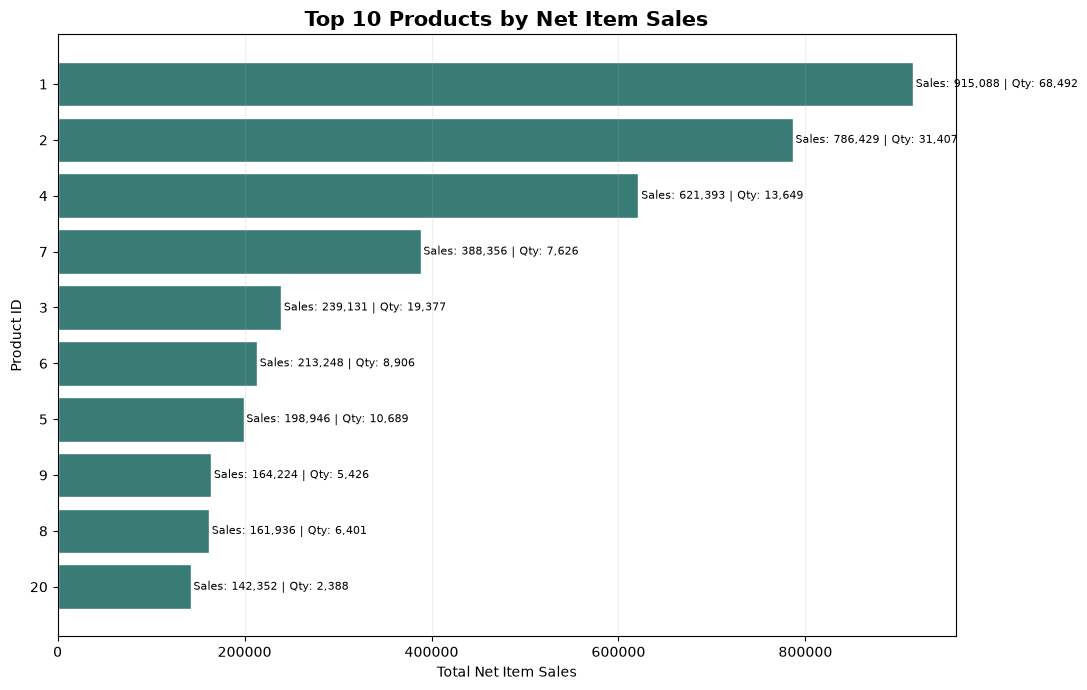

In [61]:
# Phase 3 – Step 5: Product and Category Performance
# Check 2: Product-Level Sales Performance
# Visualise the 10 products with the highest net item sales.

# Select the 10 highest-selling products
top_products = product_sales_summary.head(10).sort_values(
    "Total_Net_Sales", ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    top_products.index.astype(str),
    top_products["Total_Net_Sales"],
    color="#397B75",
    edgecolor="white"
)

# Display sales values and quantities beside each bar
for bar, quantity in zip(bars, top_products["Total_Quantity"]):
    plt.text(
        bar.get_width() + 3000,
        bar.get_y() + bar.get_height() / 2,
        f"Sales: {bar.get_width():,.0f} | Qty: {quantity:,}",
        va="center",
        fontsize=8
    )

plt.title("Top 10 Products by Net Item Sales", fontsize=15, fontweight="bold")
plt.xlabel("Total Net Item Sales")
plt.ylabel("Product ID")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 6 – Payment and Transaction Analysis

### Check 1: Payment Status Distribution

Payment Status Distribution:
          Payment_Count  Percentage
status                             
captured          89748       94.47
failed             5252        5.53


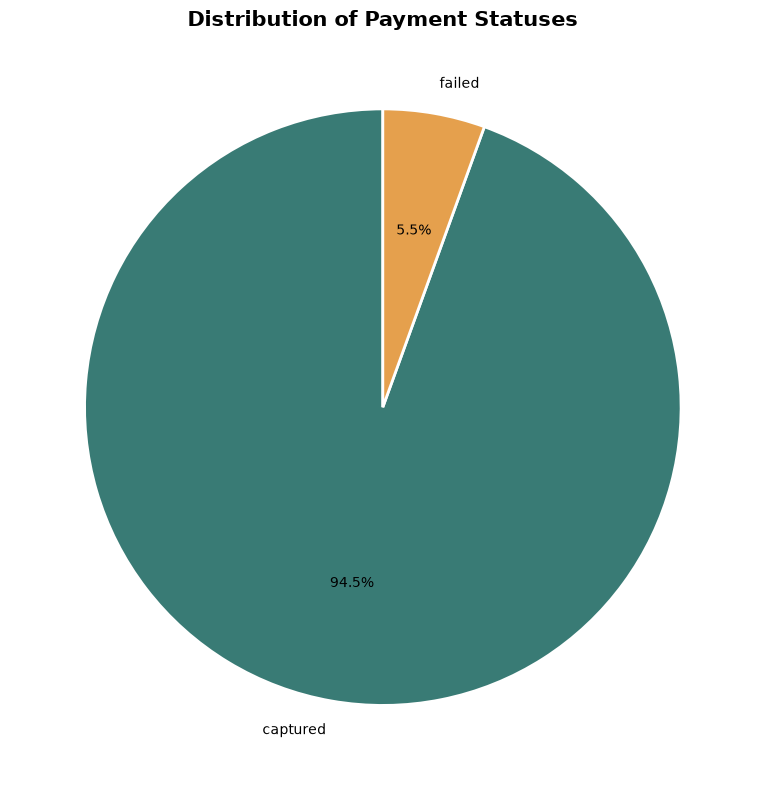

In [62]:
# Phase 3 – Step 6: Payment and Transaction Analysis
# Check 1: Payment Status Distribution
# Count payment records by status and calculate each status's percentage.

payment_summary = clean_tables["payments"]["status"].value_counts().to_frame(
    "Payment_Count"
)

payment_summary["Percentage"] = (
    payment_summary["Payment_Count"] /
    payment_summary["Payment_Count"].sum() * 100
)

print("Payment Status Distribution:")
print(payment_summary.round(2))

# Visualise the proportion of each payment status
plt.figure(figsize=(8, 8))

plt.pie(
    payment_summary["Payment_Count"],
    labels=payment_summary.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#397B75", "#E5A04D", "#8E79B5", "#D97777"][:len(payment_summary)],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title("Distribution of Payment Statuses", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## Step 7 – Returns and Refund Analysis

### Check 1: Product Return Rate

PRODUCT RETURN RATE
----------------------------------------
Total unique order items: 215,000
Unique returned order items: 12,000
Items not returned: 203,000
Product return rate: 5.58%
Non-return rate: 94.42%


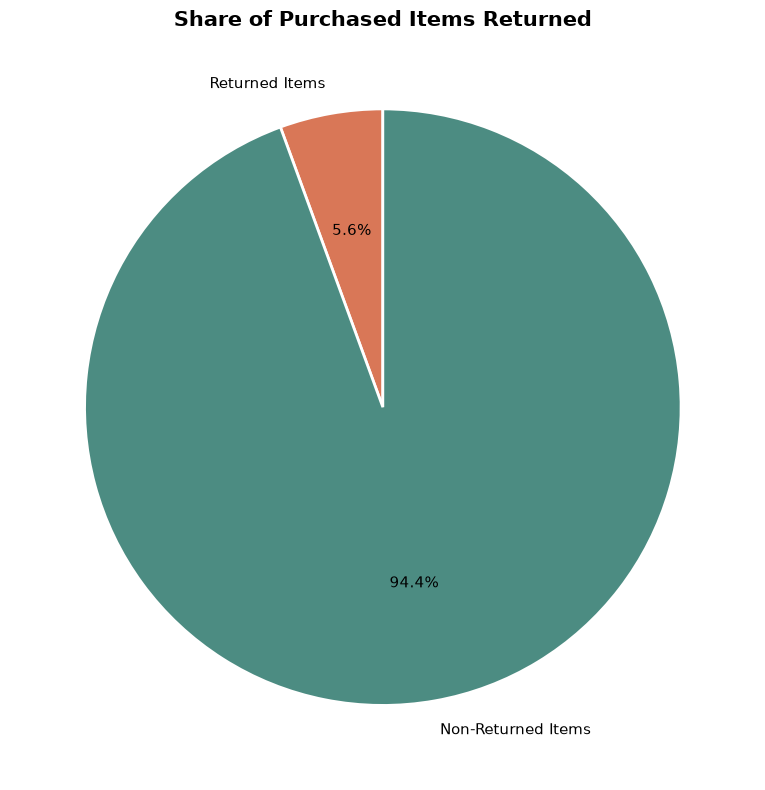

In [63]:
# Phase 3 – Step 7: Returns and Refund Analysis
# Check 1: Product Return Rate
# Compare the number of uniquely returned order items with all purchased order items.

# Load the order items and returns tables
order_items_data = clean_tables["order_items"].copy()
returns_data = clean_tables["returns"].copy()

# Count total purchased order items
total_order_items = order_items_data["order_item_id"].nunique()

# Count unique order items that have at least one return record
returned_order_items = returns_data["order_item_id"].nunique()

# Calculate items that were not returned
not_returned_items = total_order_items - returned_order_items

# Calculate the percentage of purchased items returned
return_rate = (returned_order_items / total_order_items) * 100
non_return_rate = (not_returned_items / total_order_items) * 100

# Display the results
print("PRODUCT RETURN RATE")
print("-" * 40)
print(f"Total unique order items: {total_order_items:,}")
print(f"Unique returned order items: {returned_order_items:,}")
print(f"Items not returned: {not_returned_items:,}")
print(f"Product return rate: {return_rate:.2f}%")
print(f"Non-return rate: {non_return_rate:.2f}%")

# Visualise returned versus non-returned order items
plt.figure(figsize=(8, 8))

plt.pie(
    [returned_order_items, not_returned_items],
    labels=["Returned Items", "Non-Returned Items"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#D97757", "#4C8C82"],
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

plt.title("Share of Purchased Items Returned", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Check 2: Financial Impact of Product Returns

FINANCIAL IMPACT OF PRODUCT RETURNS
---------------------------------------------
Gross Value of Returned Items: 498,266.03
Discounts on Returned Items: 4,724.61
Net Value of Returned Items: 493,541.42
Total Refund Amount: 498,266.03


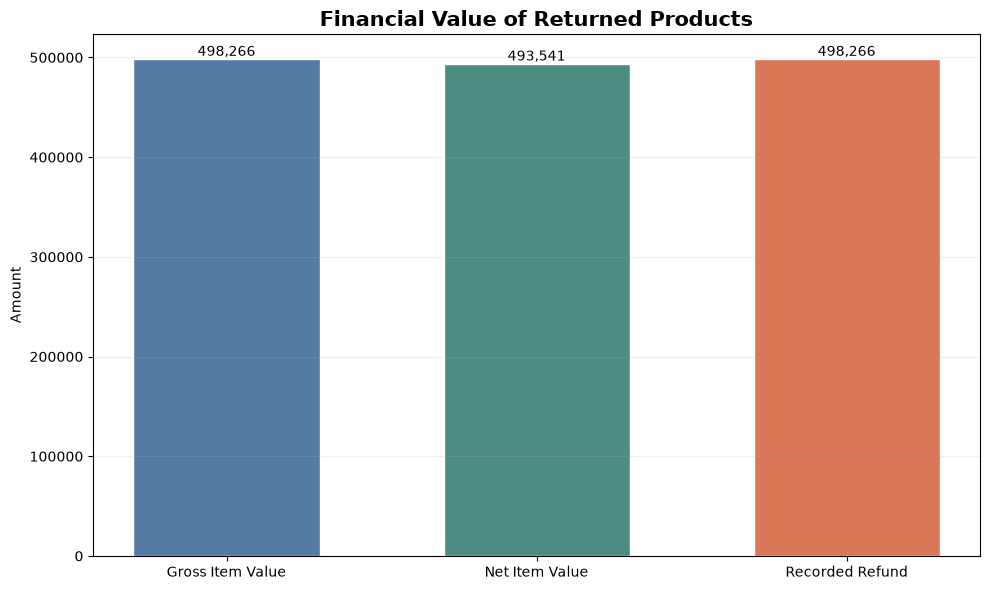

In [64]:
# Phase 3 – Step 7: Returns and Refund Analysis
# Check 2: Financial Impact of Product Returns
# Match returned items with their original sales values and calculate refund impact.

# Attach original item values to each return record
returned_sales = returns_data.merge(
    order_items_data[
        ["order_item_id", "quantity", "unit_price", "discount_amount"]
    ],
    on="order_item_id",
    how="left"
)

# Calculate the original gross and net item values
returned_sales["gross_item_value"] = (
    returned_sales["quantity"] * returned_sales["unit_price"]
)

returned_sales["net_item_value"] = (
    returned_sales["gross_item_value"] -
    returned_sales["discount_amount"]
)

# Summarise the financial impact
financial_impact = pd.Series({
    "Gross Value of Returned Items": returned_sales["gross_item_value"].sum(),
    "Discounts on Returned Items": returned_sales["discount_amount"].sum(),
    "Net Value of Returned Items": returned_sales["net_item_value"].sum(),
    "Total Refund Amount": returned_sales["refund_amount"].sum()
})

print("FINANCIAL IMPACT OF PRODUCT RETURNS")
print("-" * 45)

for metric, value in financial_impact.items():
    print(f"{metric}: {value:,.2f}")

# Compare returned item net value with recorded refunds
plt.figure(figsize=(10, 6))

comparison_labels = [
    "Gross Item Value",
    "Net Item Value",
    "Recorded Refund"
]

comparison_values = [
    financial_impact["Gross Value of Returned Items"],
    financial_impact["Net Value of Returned Items"],
    financial_impact["Total Refund Amount"]
]

bars = plt.bar(
    comparison_labels,
    comparison_values,
    color=["#547AA5", "#4C8C82", "#D97757"],
    edgecolor="white",
    width=0.6
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Financial Value of Returned Products", fontsize=15, fontweight="bold")
plt.ylabel("Amount")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Check 3: Return Reasons and Restocking

1. RETURN REASONS AND REFUND IMPACT
                  Return_Count Total_Refund Average_Refund  Return_Percentage  \
reason                                                                          
changed_mind              3739    154362.93      41.284549              31.16   
damaged                   3384    139291.37      41.161752              28.20   
not_as_described          2862    119811.44      41.862837              23.85   
wrong_item                2015     84800.29      42.084511              16.79   

                          Refund_Contribution_%  
reason                                           
changed_mind      30.98002286047876874126859501  
damaged           27.95522102921605954152644121  
not_as_described  24.04567696497391162708804371  
wrong_item        17.01907914533126009011692007  

2. RESTOCKING ANALYSIS
           Return_Count Total_Refund Average_Refund  Return_Percentage  \
restocked                                                                
False

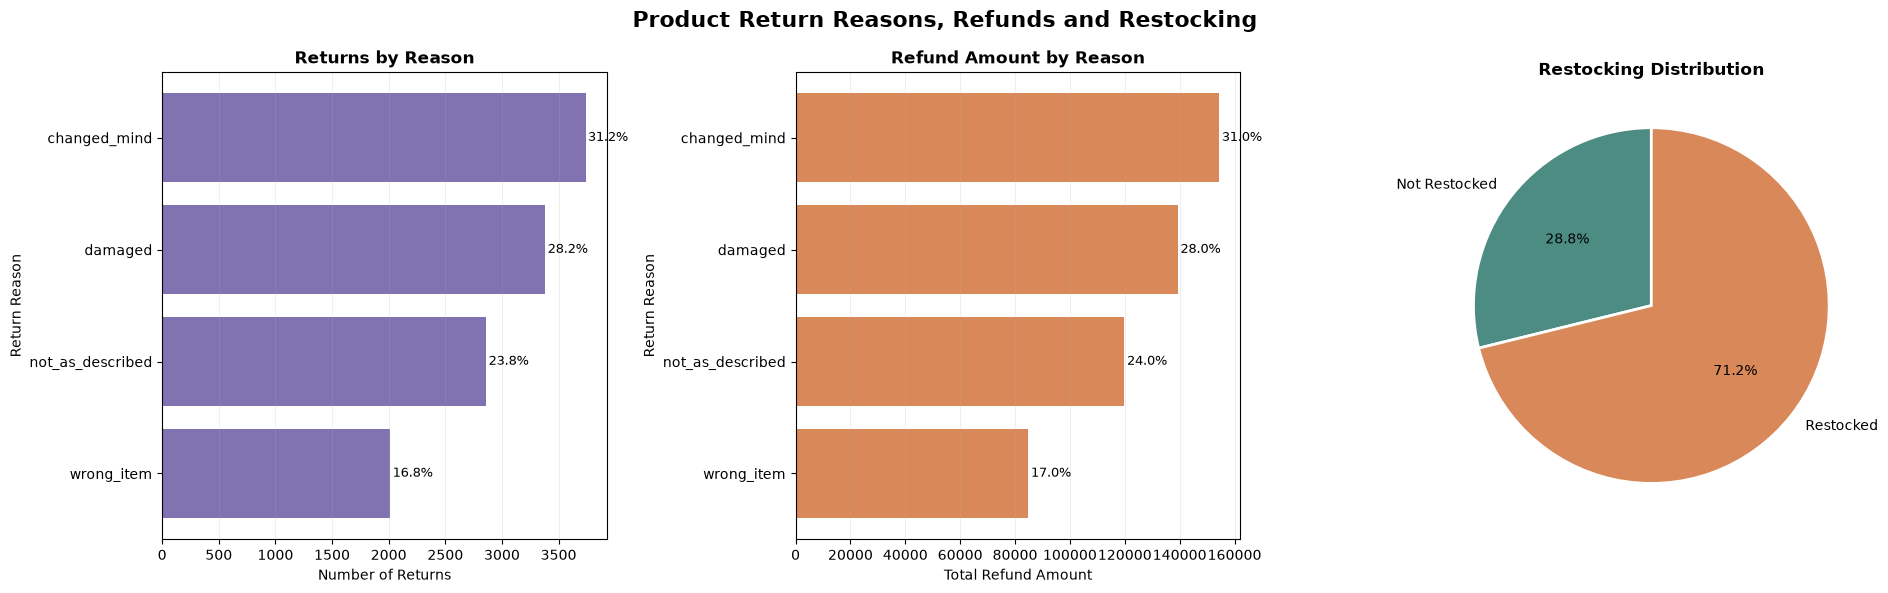

In [65]:

# Phase 3 – Step 7: Returns and Refund Analysis
# Check 3: Return Reasons, Refund Impact and Restocking
# Analyse return reasons, refund amounts and restocking outcomes together.

import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Return Reasons Analysis
# --------------------------------------------------

reason_summary = returns_data.groupby("reason").agg(
    Return_Count=("return_id", "count"),
    Total_Refund=("refund_amount", "sum"),
    Average_Refund=("refund_amount", "mean")
)

reason_summary["Return_Percentage"] = (
    reason_summary["Return_Count"] /
    reason_summary["Return_Count"].sum() * 100
)

reason_summary["Refund_Contribution_%"] = (
    reason_summary["Total_Refund"] /
    reason_summary["Total_Refund"].sum() * 100
)

print("1. RETURN REASONS AND REFUND IMPACT")
print(reason_summary.sort_values("Return_Count", ascending=False).round(2))


# --------------------------------------------------
# 2. Restocking Analysis
# --------------------------------------------------

restock_summary = returns_data.groupby("restocked").agg(
    Return_Count=("return_id", "count"),
    Total_Refund=("refund_amount", "sum"),
    Average_Refund=("refund_amount", "mean")
)

restock_summary["Return_Percentage"] = (
    restock_summary["Return_Count"] /
    restock_summary["Return_Count"].sum() * 100
)

restock_summary["Refund_Contribution_%"] = (
    restock_summary["Total_Refund"] /
    restock_summary["Total_Refund"].sum() * 100
)

print("\n2. RESTOCKING ANALYSIS")
print(restock_summary.round(2))


# --------------------------------------------------
# 3. Visualisation: Return Reasons
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

reason_plot = reason_summary.sort_values("Return_Count")

axes[0].barh(
    reason_plot.index,
    reason_plot["Return_Count"],
    color="#8172B2"
)

for i, percentage in enumerate(reason_plot["Return_Percentage"]):
    axes[0].text(
        reason_plot["Return_Count"].iloc[i] + 20,
        i,
        f"{percentage:.1f}%",
        va="center",
        fontsize=9
    )

axes[0].set_title("Returns by Reason", fontweight="bold")
axes[0].set_xlabel("Number of Returns")
axes[0].set_ylabel("Return Reason")
axes[0].grid(axis="x", alpha=0.2)


# --------------------------------------------------
# 4. Visualisation: Refund Amount by Reason
# --------------------------------------------------

refund_plot = reason_summary.sort_values("Total_Refund")

axes[1].barh(
    refund_plot.index,
    refund_plot["Total_Refund"],
    color="#D98959"
)

for i, percentage in enumerate(refund_plot["Refund_Contribution_%"]):
    axes[1].text(
        refund_plot["Total_Refund"].iloc[i] + 1000,
        i,
        f"{percentage:.1f}%",
        va="center",
        fontsize=9
    )

axes[1].set_title("Refund Amount by Reason", fontweight="bold")
axes[1].set_xlabel("Total Refund Amount")
axes[1].set_ylabel("Return Reason")
axes[1].grid(axis="x", alpha=0.2)


# --------------------------------------------------
# 5. Visualisation: Restocking Distribution
# --------------------------------------------------

restock_labels = [
    "Restocked" if value else "Not Restocked"
    for value in restock_summary.index
]

axes[2].pie(
    restock_summary["Return_Count"],
    labels=restock_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C8C82", "#D98959"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

axes[2].set_title("Restocking Distribution", fontweight="bold")

plt.suptitle(
    "Product Return Reasons, Refunds and Restocking",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Check 4: Overall Return Financial Impact

OVERALL RETURN FINANCIAL IMPACT
---------------------------------------------
Total Net Item Sales: 9,024,059.76
Net Value of Returned Items: 493,541.42
Total Recorded Refunds: 498,266.03
Returned Net Value / Total Sales: 5.47%
Refunds / Total Net Item Sales: 5.52%

FINANCIAL IMPACT BY RESTOCKING STATUS
          Total_Refund Returned_Net_Value  Return_Count
restocked                                              
False        146794.24          145327.32          3462
True         351471.79          348214.10          8538


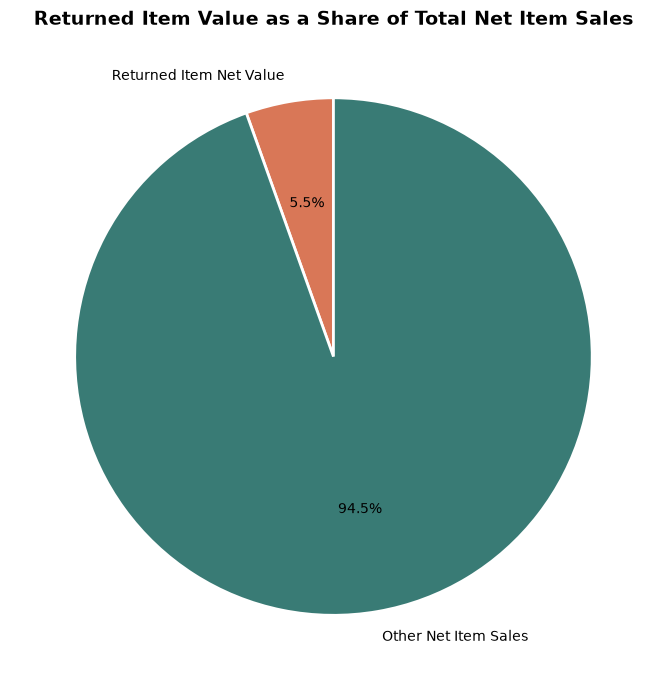

In [68]:

# Phase 3 – Step 7: Returns and Refund Analysis
# Check 4: Overall Return Financial Impact
# Calculate return-related financial impact and generate the visualisation.

# Calculate total sales and return-related values as numeric floats
total_net_sales = float(pd.to_numeric(sales_data["net_item_value"]).sum())

total_returned_net_value = float(
    pd.to_numeric(returned_sales["net_item_value"]).sum()
)

total_refunds = float(
    pd.to_numeric(returned_sales["refund_amount"]).sum()
)

# Calculate percentages
returned_sales_percentage = (
    total_returned_net_value / total_net_sales * 100
)

refund_sales_percentage = (
    total_refunds / total_net_sales * 100
)

# Display overall financial impact
print("OVERALL RETURN FINANCIAL IMPACT")
print("-" * 45)
print(f"Total Net Item Sales: {total_net_sales:,.2f}")
print(f"Net Value of Returned Items: {total_returned_net_value:,.2f}")
print(f"Total Recorded Refunds: {total_refunds:,.2f}")
print(f"Returned Net Value / Total Sales: {returned_sales_percentage:.2f}%")
print(f"Refunds / Total Net Item Sales: {refund_sales_percentage:.2f}%")

# Analyse financial impact by restocking status
restock_financial = returned_sales.groupby("restocked").agg(
    Total_Refund=("refund_amount", "sum"),
    Returned_Net_Value=("net_item_value", "sum"),
    Return_Count=("return_id", "count")
)

print("\nFINANCIAL IMPACT BY RESTOCKING STATUS")
print(restock_financial.round(2))

# Visualise returned item value against other net item sales
returned_value = float(total_returned_net_value)
other_sales_value = float(total_net_sales - total_returned_net_value)

plt.figure(figsize=(9, 7))

plt.pie(
    [returned_value, other_sales_value],
    labels=["Returned Item Net Value", "Other Net Item Sales"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#D97757", "#397B75"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title(
    "Returned Item Value as a Share of Total Net Item Sales",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


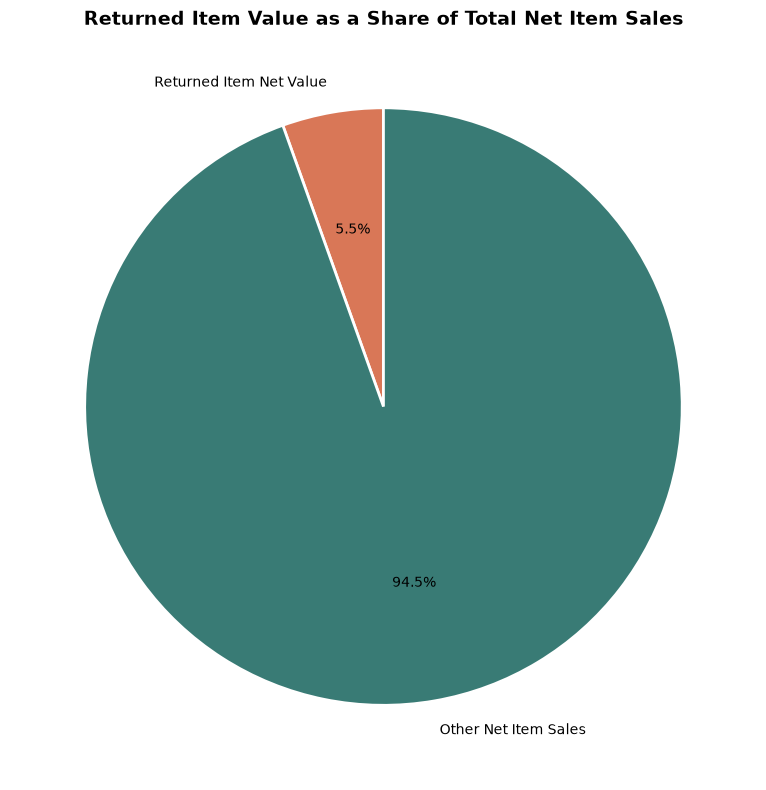

In [67]:

# Phase 3 – Step 7: Returns and Refund Analysis
# Check 4: Overall Return Financial Impact – Graph Fix
# Convert financial values to floats so Matplotlib can plot them.

returned_value = float(total_returned_net_value)
other_sales_value = float(total_net_sales - total_returned_net_value)

plt.figure(figsize=(8, 8))

plt.pie(
    [returned_value, other_sales_value],
    labels=["Returned Item Net Value", "Other Net Item Sales"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#D97757", "#397B75"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title(
    "Returned Item Value as a Share of Total Net Item Sales",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Check 5: Return Rate by Product Category

RETURN RATE BY PRODUCT CATEGORY
-------------------------------------------------------
                Total_Order_Items  Returned_Items Total_Net_Sales  \
category_name                                                       
Sprinklers                   3422             209       212992.33   
Lighting                     3420             207       160078.45   
Drip Systems                 3414             205       147317.39   
Bagged Soil                 14589             847       689400.69   
Soil & Compost               3739             217       178459.37   
Plants                       5309             308       148479.49   
Garden Tools                21088            1220       616088.14   
Shrubs                       4097             235       112930.15   
Fire Pits                   12337             700       725974.87   
Hoses                       11380             645       766107.46   
Festoon                      4836             274       245125.84   
Furniture      

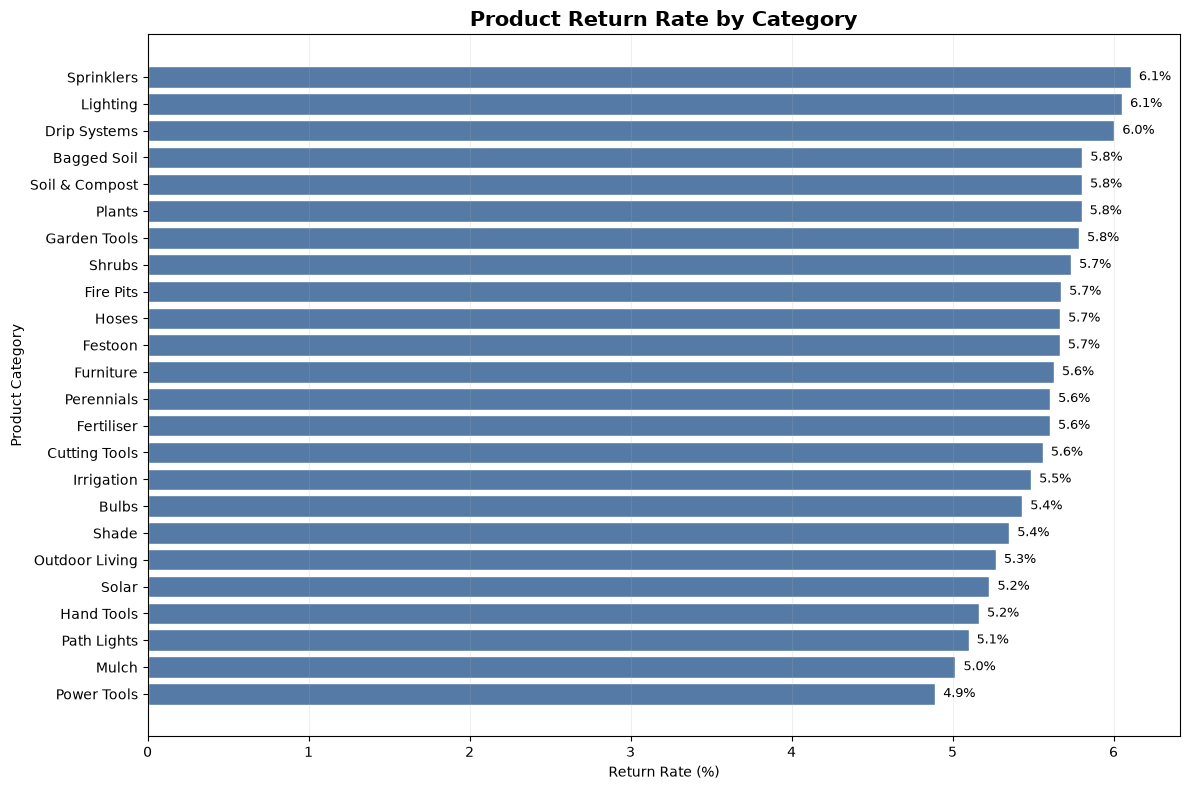

In [70]:

# Phase 3 – Step 7: Returns and Refund Analysis
# Check 5: Return Rate by Product Category
# Compare returned items with purchased items in each product category.

# Start with order items and attach the calculated sales values
all_items = sales_data[
    ["order_item_id", "product_id", "order_id", "net_item_value"]
].copy()

# Attach category information to each purchased item
all_items = all_items.merge(
    clean_tables["products"][["product_id", "category_id"]],
    on="product_id",
    how="left"
)

all_items = all_items.merge(
    clean_tables["categories"][["category_id", "category_name"]],
    on="category_id",
    how="left"
)

# Identify uniquely returned order items
returned_item_ids = returns_data["order_item_id"].drop_duplicates()

all_items["was_returned"] = (
    all_items["order_item_id"].isin(returned_item_ids)
)

# Calculate category-level purchase and return counts
category_return_summary = all_items.groupby("category_name").agg(
    Total_Order_Items=("order_item_id", "nunique"),
    Returned_Items=("was_returned", "sum"),
    Total_Net_Sales=("net_item_value", "sum")
)

# Calculate return rate for each category
category_return_summary["Return_Rate_%"] = (
    category_return_summary["Returned_Items"] /
    category_return_summary["Total_Order_Items"] * 100
)

# Sort categories by return rate
category_return_summary = category_return_summary.sort_values(
    "Return_Rate_%", ascending=False
)

print("RETURN RATE BY PRODUCT CATEGORY")
print("-" * 55)
print(category_return_summary.round(2))

print("\nHIGHEST RETURN RATE:")
print(category_return_summary.index[0],
      f"- {category_return_summary['Return_Rate_%'].iloc[0]:.2f}%")

print("\nLOWEST RETURN RATE:")
print(category_return_summary.index[-1],
      f"- {category_return_summary['Return_Rate_%'].iloc[-1]:.2f}%")

# Visualise category return rates
plt.figure(figsize=(12, 8))

category_plot = category_return_summary.sort_values("Return_Rate_%")

bars = plt.barh(
    category_plot.index,
    category_plot["Return_Rate_%"],
    color="#547AA5",
    edgecolor="white"
)

for bar in bars:
    plt.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=9
    )

plt.title("Product Return Rate by Category", fontsize=15, fontweight="bold")
plt.xlabel("Return Rate (%)")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### Check 6: Return Reasons Across Product Categories

RETURN REASONS ACROSS PRODUCT CATEGORIES
-------------------------------------------------------
category_name     Bagged Soil  Bulbs  Cutting Tools  Drip Systems  Fertiliser  \
reason                                                                          
changed_mind              274    458             76            69         863   
damaged                   228    391             68            57         827   
not_as_described          213    351             65            47         642   
wrong_item                132    247             42            32         482   

category_name     Festoon  Fire Pits  Furniture  Garden Tools  Hand Tools  \
reason                                                                      
changed_mind           76        236         73           375         109   
damaged                88        193         63           353         104   
not_as_described       61        158         47           287          90   
wrong_item             49      

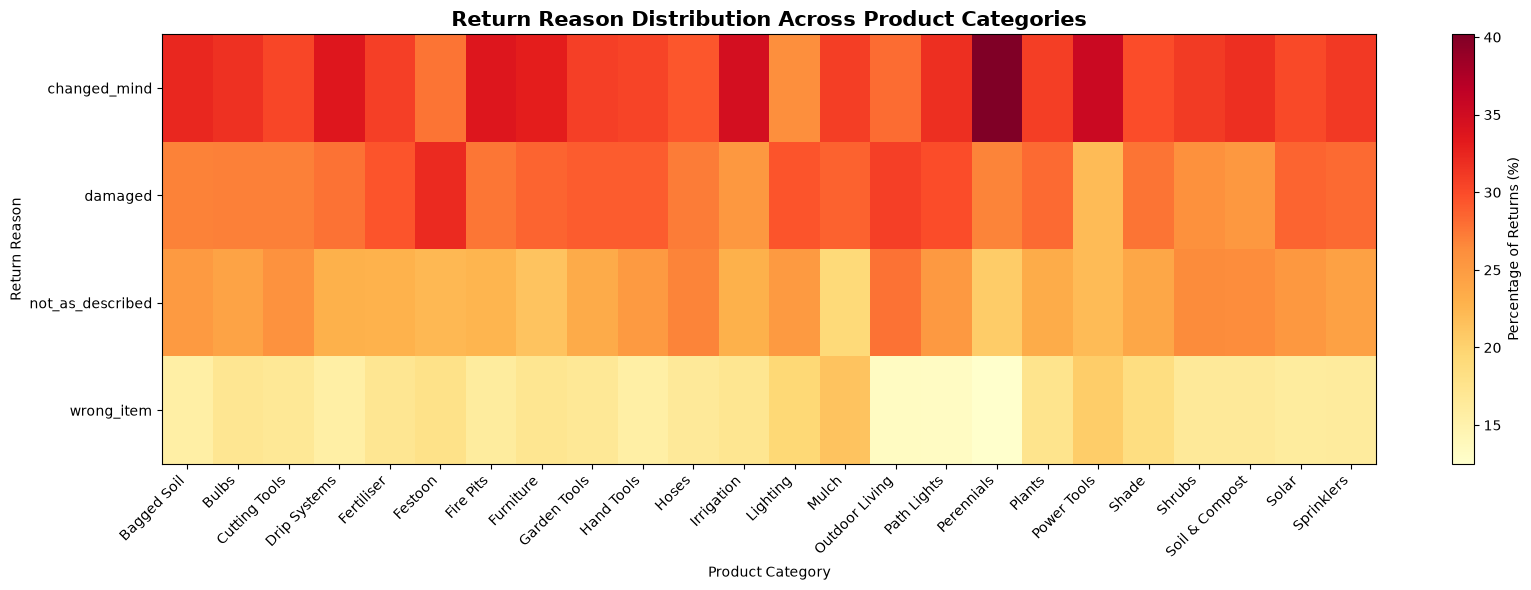

In [71]:

# Phase 3 – Step 7: Returns and Refund Analysis
# Check 6: Return Reasons Across Product Categories
# Examine how return reasons differ across product categories.

# Attach product category information to return records
return_category_data = returns_data.merge(
    order_items_data[["order_item_id", "product_id"]],
    on="order_item_id",
    how="left"
).merge(
    clean_tables["products"][["product_id", "category_id"]],
    on="product_id",
    how="left"
).merge(
    clean_tables["categories"][["category_id", "category_name"]],
    on="category_id",
    how="left"
)

# Create a matrix of return reasons and product categories
reason_category_matrix = pd.crosstab(
    return_category_data["reason"],
    return_category_data["category_name"]
)

# Convert counts into percentages within each category
reason_category_percentage = (
    reason_category_matrix.div(
        reason_category_matrix.sum(axis=0), axis=1
    ) * 100
)

print("RETURN REASONS ACROSS PRODUCT CATEGORIES")
print("-" * 55)
print(reason_category_matrix)

print("\nRETURN REASON PERCENTAGES WITHIN EACH CATEGORY")
print(reason_category_percentage.round(1))

# Visualise the percentage distribution using a heatmap
plt.figure(figsize=(17, 6))

heatmap = plt.imshow(
    reason_category_percentage,
    cmap="YlOrRd",
    aspect="auto"
)

plt.colorbar(heatmap, label="Percentage of Returns (%)")

plt.xticks(
    range(len(reason_category_percentage.columns)),
    reason_category_percentage.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(reason_category_percentage.index)),
    reason_category_percentage.index
)

plt.title(
    "Return Reason Distribution Across Product Categories",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Return Reason")

plt.tight_layout()
plt.show()


## Step 8 – Cross-Dimensional Analysis

### Check 1: Sales Contribution and Return Rate by Category

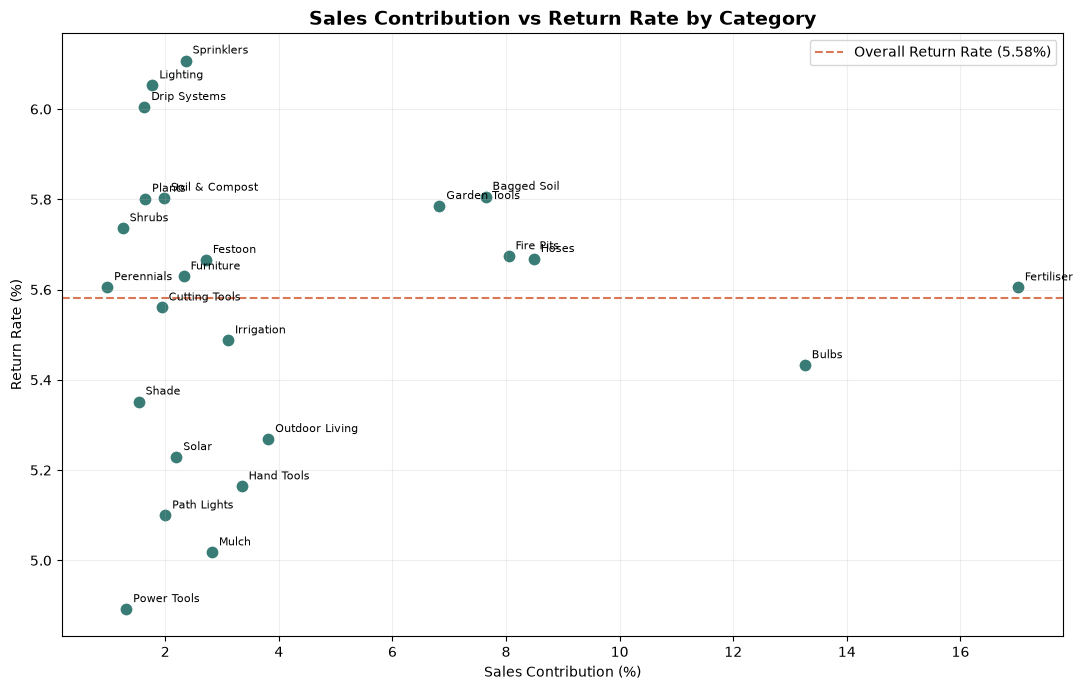

In [75]:

# Phase 3 – Step 8: Cross-Dimensional Analysis
# Check 1: Sales Contribution vs Return Rate by Category
# Use a simple scatter plot to make category comparisons easier.

plt.figure(figsize=(11, 7))

plt.scatter(
    category_comparison["Sales_Contribution_%"],
    category_comparison["Return_Rate_%"],
    color="#397B75",
    s=90,
    edgecolors="white"
)

# Label each category
for category, row in category_comparison.iterrows():
    plt.annotate(
        category,
        (row["Sales_Contribution_%"], row["Return_Rate_%"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(
    average_return_rate,
    color="#D97757",
    linestyle="--",
    label=f"Overall Return Rate ({average_return_rate:.2f}%)"
)

plt.title(
    "Sales Contribution vs Return Rate by Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sales Contribution (%)")
plt.ylabel("Return Rate (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Check 2: Restocked and Non-Restocked Return Impact

FINANCIAL IMPACT BY RESTOCKING STATUS
--------------------------------------------------
           Return_Count  Total_Refund  Average_Refund  Refund_Contribution_%  \
restocked                                                                      
False              3462     146794.24           42.40                  29.46   
True               8538     351471.79           41.17                  70.54   

                   Group  
restocked                 
False      Not Restocked  
True           Restocked  


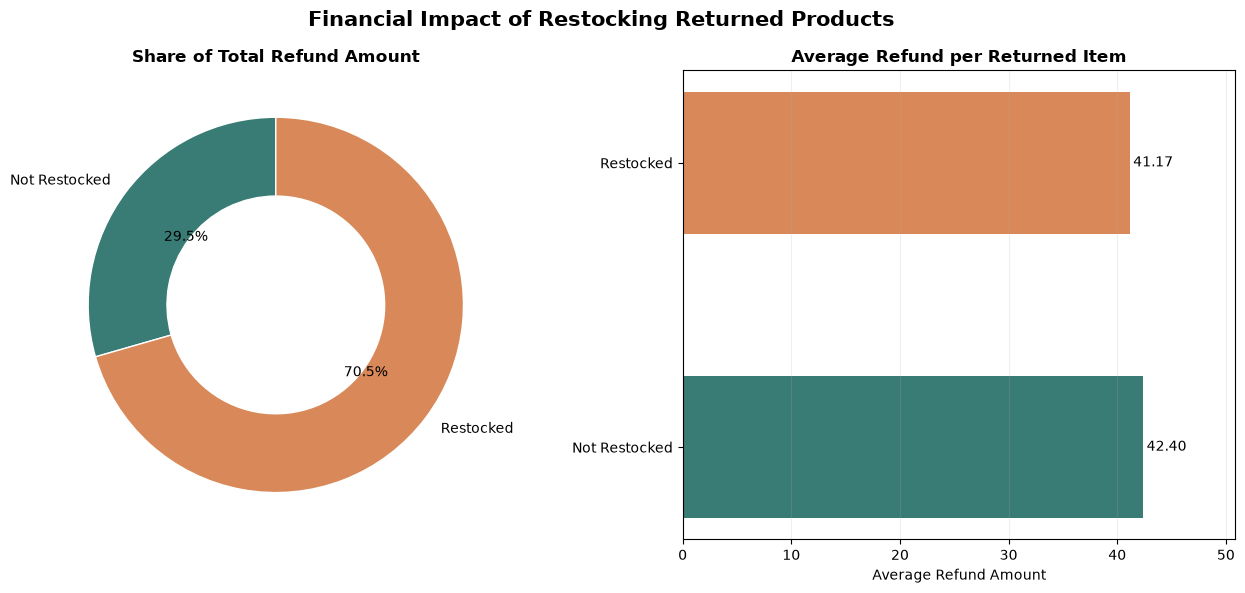

In [78]:

# Phase 3 – Step 8: Cross-Dimensional Analysis
# Check 2: Financial Impact of Restocked vs Non-Restocked Returns
# Compare refund contribution and average refund by restocking status.

# Calculate financial metrics for each restocking group
restock_impact = returns_data.groupby("restocked").agg(
    Return_Count=("return_id", "count"),
    Total_Refund=("refund_amount", "sum"),
    Average_Refund=("refund_amount", "mean")
)

# Explicitly convert financial columns into numeric values
for column in ["Total_Refund", "Average_Refund"]:
    restock_impact[column] = pd.to_numeric(
        restock_impact[column], errors="raise"
    ).astype(float)

# Calculate refund contribution percentage
restock_impact["Refund_Contribution_%"] = (
    restock_impact["Total_Refund"] /
    restock_impact["Total_Refund"].sum() * 100
)

# Create readable labels
restock_impact["Group"] = [
    "Restocked" if value else "Not Restocked"
    for value in restock_impact.index
]

restock_impact = restock_impact.sort_values("Group")

print("FINANCIAL IMPACT BY RESTOCKING STATUS")
print("-" * 50)
print(restock_impact.round(2))

# Extract numeric values for plotting
refund_values = restock_impact["Total_Refund"].to_numpy(dtype=float)
average_values = restock_impact["Average_Refund"].to_numpy(dtype=float)
group_labels = restock_impact["Group"].astype(str).to_numpy()

# Create visualisations
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Doughnut chart: share of total refunds
axes[0].pie(
    refund_values,
    labels=group_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#397B75", "#D98959"],
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

axes[0].set_title("Share of Total Refund Amount", fontweight="bold")

# Horizontal bars: average refund per returned item
bars = axes[1].barh(
    group_labels,
    average_values,
    color=["#397B75", "#D98959"],
    height=0.5
)

for bar in bars:
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

axes[1].set_xlim(0, max(average_values) * 1.2)
axes[1].set_title("Average Refund per Returned Item", fontweight="bold")
axes[1].set_xlabel("Average Refund Amount")
axes[1].grid(axis="x", alpha=0.2)

plt.suptitle(
    "Financial Impact of Restocking Returned Products",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Check 3: Monthly Return Trends

MONTHLY RETURN TRENDS
---------------------------------------------
              Return_Count Total_Refund
Return_Month                           
2023-01-01             316     12210.42
2023-02-01             256     10019.76
2023-03-01             332     14044.64
2023-04-01             287     11468.24
2023-05-01             331     13013.23
2023-06-01             286     12194.68
2023-07-01             314     12045.70
2023-08-01             323     12670.85
2023-09-01             296     12005.98
2023-10-01             292     11892.72
2023-11-01             467     20085.74
2023-12-01             528     22205.43
2024-01-01             350     12726.00
2024-02-01             289     12500.56
2024-03-01             293     11652.86
2024-04-01             305     12027.07
2024-05-01             310     13337.83
2024-06-01             293     12650.14
2024-07-01             307     12404.80
2024-08-01             339     14356.74
2024-09-01             262     11916.60
2024-10-01  

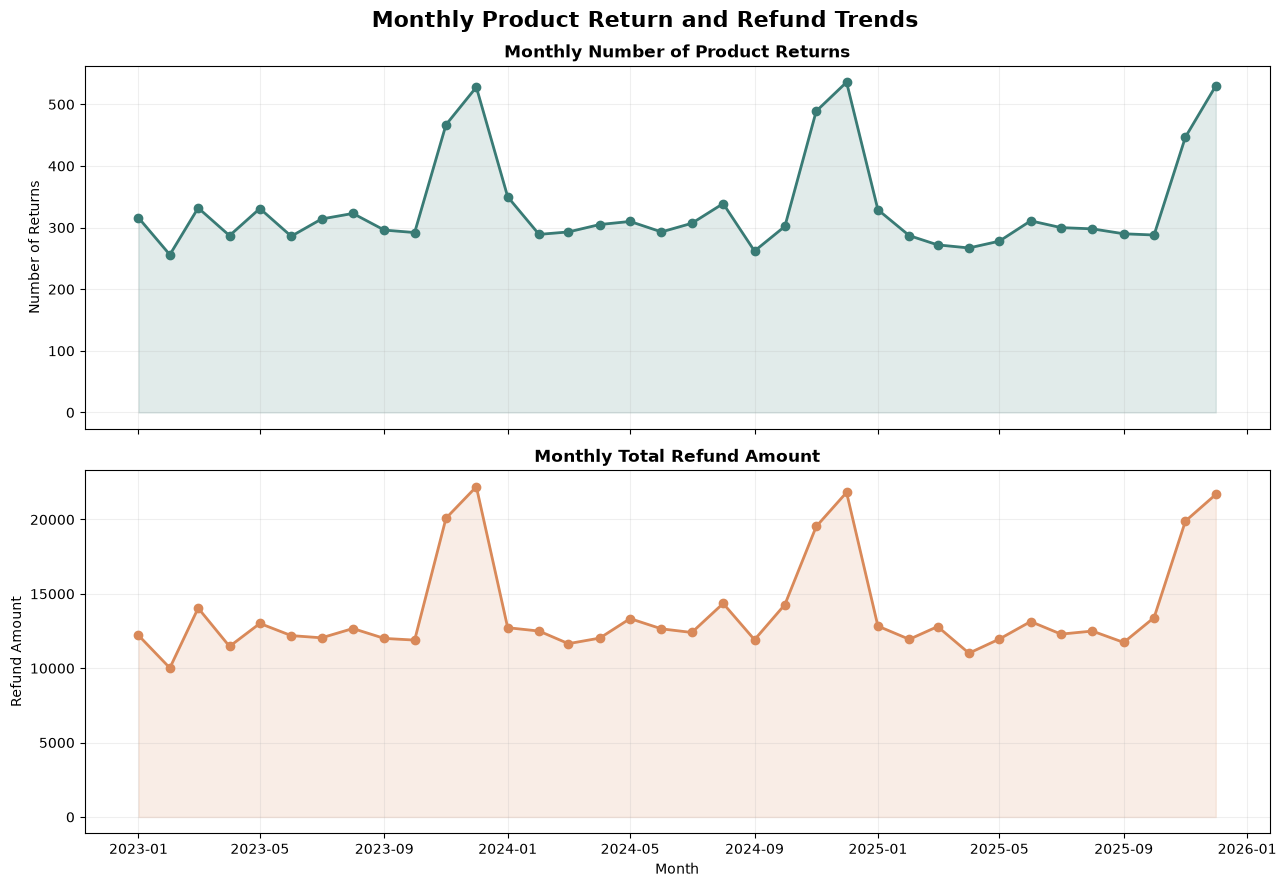

In [79]:

# Phase 3 – Step 8: Cross-Dimensional Analysis
# Check 3: Monthly Return Trends
# Examine monthly return counts and refund amounts over time.

# Convert return timestamps into datetime format
monthly_returns_data = returns_data.copy()

monthly_returns_data["returned_at"] = pd.to_datetime(
    monthly_returns_data["returned_at"]
)

# Extract year and month from return dates
monthly_returns_data["Return_Month"] = (
    monthly_returns_data["returned_at"].dt.to_period("M")
)

# Calculate monthly return counts and refund amounts
monthly_return_summary = monthly_returns_data.groupby(
    "Return_Month"
).agg(
    Return_Count=("return_id", "count"),
    Total_Refund=("refund_amount", "sum")
)

# Convert period index to timestamps for plotting
monthly_return_summary.index = (
    monthly_return_summary.index.to_timestamp()
)

print("MONTHLY RETURN TRENDS")
print("-" * 45)
print(monthly_return_summary.round(2))

print("\nHighest return month:")
print(monthly_return_summary["Return_Count"].idxmax().strftime("%B %Y"))

print("\nHighest refund month:")
print(monthly_return_summary["Total_Refund"].idxmax().strftime("%B %Y"))

# Ensure plotting columns are numeric
monthly_return_summary["Return_Count"] = pd.to_numeric(
    monthly_return_summary["Return_Count"]
).astype(float)

monthly_return_summary["Total_Refund"] = pd.to_numeric(
    monthly_return_summary["Total_Refund"]
).astype(float)

# Create two monthly trend visualisations
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# Monthly return count trend
axes[0].plot(
    monthly_return_summary.index,
    monthly_return_summary["Return_Count"],
    color="#397B75",
    marker="o",
    linewidth=2
)

axes[0].fill_between(
    monthly_return_summary.index,
    monthly_return_summary["Return_Count"],
    color="#397B75",
    alpha=0.15
)

axes[0].set_title("Monthly Number of Product Returns", fontweight="bold")
axes[0].set_ylabel("Number of Returns")
axes[0].grid(alpha=0.2)

# Monthly refund amount trend
axes[1].plot(
    monthly_return_summary.index,
    monthly_return_summary["Total_Refund"],
    color="#D98959",
    marker="o",
    linewidth=2
)

axes[1].fill_between(
    monthly_return_summary.index,
    monthly_return_summary["Total_Refund"],
    color="#D98959",
    alpha=0.15
)

axes[1].set_title("Monthly Total Refund Amount", fontweight="bold")
axes[1].set_ylabel("Refund Amount")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.2)

plt.suptitle(
    "Monthly Product Return and Refund Trends",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Check 4 and 5: Return Impact by Order Status and Financial Summary

RETURN AND REFUND IMPACT BY ORDER STATUS
-------------------------------------------------------
            Return_Count Total_Refund Returned_Net_Value  \
status                                                     
cancelled            693     28088.87           27862.95   
delivered           8640    360949.43          357475.06   
processing           726     29026.69           28742.81   
returned             618     25167.62           24955.02   
shipped             1323     55033.42           54505.58   

                    Refund_Contribution_%  
status                                     
cancelled   5.637323901049405274527745751  
delivered   72.44110741404546482930012307  
processing  5.825540625356298120504020714  
returned    5.051040706106334401323726604  
shipped     11.04498735344249737434438386  

OVERALL PROJECT FINANCIAL SUMMARY
-------------------------------------------------------
Total Net Item Sales: 9,024,059.76
Net Value of Returned Items: 493,541.42
Total Re

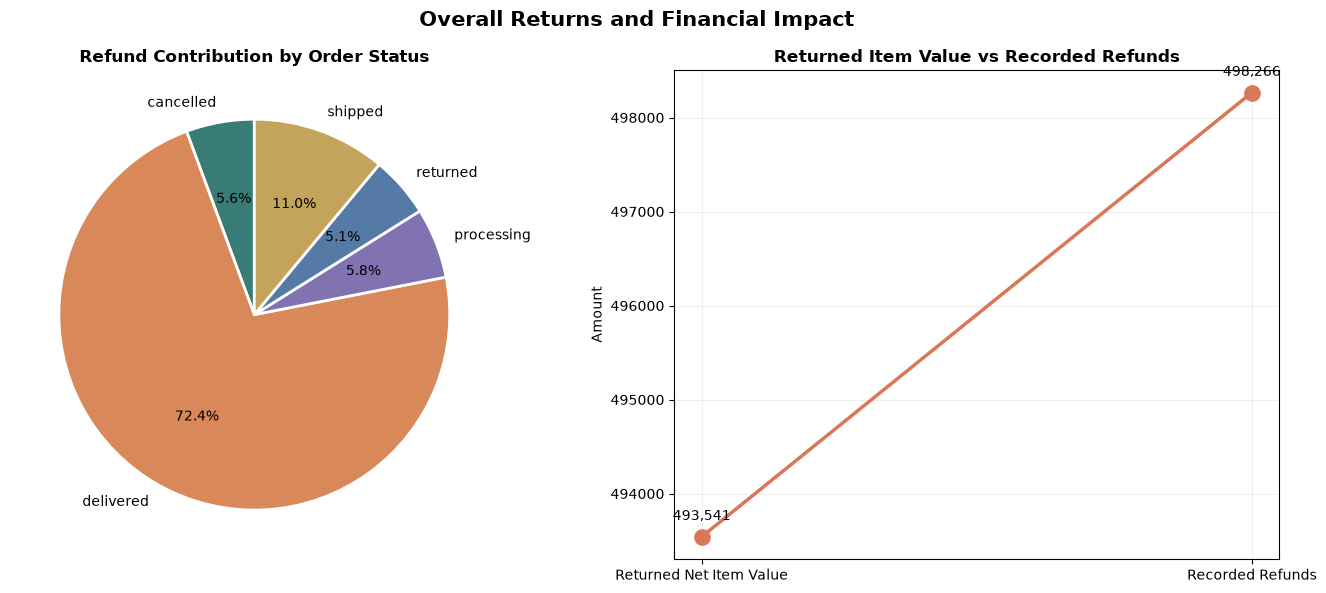

In [81]:

# Phase 3 – Step 8: Cross-Dimensional Analysis
# Check 4 & 5: Return Impact by Order Status and Overall Financial Summary
# Rebuild returned item data with order IDs, analyse status and summarise financial impact.

# Attach order IDs and calculated net item values to return records
status_return_data = returns_data.merge(
    sales_data[["order_item_id", "order_id", "net_item_value"]],
    on="order_item_id",
    how="left"
)

# Attach order status to returned items
status_return_data = status_return_data.merge(
    clean_tables["orders"][["order_id", "status"]],
    on="order_id",
    how="left"
)

# Calculate return and refund impact by order status
status_return_summary = status_return_data.groupby("status").agg(
    Return_Count=("return_id", "count"),
    Total_Refund=("refund_amount", "sum"),
    Returned_Net_Value=("net_item_value", "sum")
)

status_return_summary["Refund_Contribution_%"] = (
    status_return_summary["Total_Refund"] /
    status_return_summary["Total_Refund"].sum() * 100
)

print("RETURN AND REFUND IMPACT BY ORDER STATUS")
print("-" * 55)
print(status_return_summary.round(2))

# Calculate overall financial summary
total_net_sales = float(sales_data["net_item_value"].sum())
total_returned_value = float(status_return_data["net_item_value"].sum())
total_refunds = float(status_return_data["refund_amount"].sum())

total_purchased_items = sales_data["order_item_id"].nunique()
total_returned_items = status_return_data["order_item_id"].nunique()

overall_return_rate = (
    total_returned_items / total_purchased_items * 100
)

print("\nOVERALL PROJECT FINANCIAL SUMMARY")
print("-" * 55)
print(f"Total Net Item Sales: {total_net_sales:,.2f}")
print(f"Net Value of Returned Items: {total_returned_value:,.2f}")
print(f"Total Recorded Refunds: {total_refunds:,.2f}")
print(f"Total Purchased Items: {total_purchased_items:,}")
print(f"Total Returned Items: {total_returned_items:,}")
print(f"Overall Item Return Rate: {overall_return_rate:.2f}%")

# Prepare numeric values for visualisation
refund_values = pd.to_numeric(
    status_return_summary["Total_Refund"]
).to_numpy(dtype=float)

status_labels = status_return_summary.index.astype(str)

# Create two visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visualisation 1: Refund contribution by order status
axes[0].pie(
    refund_values,
    labels=status_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#397B75", "#D98959", "#8172B2", "#547AA5", "#C4A35A"][:len(refund_values)],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

axes[0].set_title(
    "Refund Contribution by Order Status",
    fontweight="bold"
)

# Visualisation 2: Returned net value versus recorded refunds
comparison_values = [
    total_returned_value,
    total_refunds
]

axes[1].plot(
    ["Returned Net Item Value", "Recorded Refunds"],
    comparison_values,
    marker="o",
    markersize=11,
    linewidth=2.5,
    color="#D97757"
)

for i, value in enumerate(comparison_values):
    axes[1].annotate(
        f"{value:,.0f}",
        (i, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

axes[1].set_title(
    "Returned Item Value vs Recorded Refunds",
    fontweight="bold"
)
axes[1].set_ylabel("Amount")
axes[1].grid(alpha=0.2)

plt.suptitle(
    "Overall Returns and Financial Impact",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# Convert all seven Parquet tables into separate Excel sheets
tables = [
    "categories",
    "customers",
    "products",
    "orders",
    "order_items",
    "payments",
    "returns"
]

with pd.ExcelWriter("Retail_Dataset.xlsx", engine="openpyxl") as writer:
    for table in tables:
        df = pd.read_parquet(f"{table}.parquet")
        df.to_excel(writer, sheet_name=table, index=False)

print("Excel workbook created successfully!")


# Phase 4 – Business Insights and Recommendations

## Consolidated Key Findings

- The existing EDA reports total gross item sales of $9,107,788.58, discounts of $83,728.82, and net item sales of $9,024,059.76.
- The analysis records 12,000 returned order items out of 215,000 purchased order items, for an item return rate of 5.58%.
- Recorded refunds total $498,266.03. The net value of returned items after discounts is $493,541.42.
- Changed mind is the most frequent recorded return reason (3,739 records); damaged items account for 3,384 records.
- Category return rates range from 6.11% for Sprinklers to 4.89% for Power Tools in the existing category analysis.
- Return-date validation identifies 5,962 of 12,000 returns as timestamped before their corresponding order dates (49.68%).

## Financial Impact Assessment

The notebook reports net item sales of $9,024,059.76, returned net value of $493,541.42 (5.47% of net item sales), and recorded refunds of $498,266.03 (5.52% of net item sales). Refund amounts are based on gross item value, while returned net value reflects discounts; these measures should remain distinct. They describe sales and refund exposure, not actual profit loss.

The analysis cannot calculate realized profit loss because it does not establish item-level inventory recovery or resale value. Do not interpret the refund total as a profit-loss estimate.

## Business Problems Identified

- Return timestamps precede order dates for 5,962 records, limiting confidence in return timing and trend interpretation.
- The leading reasons are changed mind, damaged, not as described, and wrong item; these are areas for further investigation, not proven causes.
- Recorded refund totals exceed returned net value because refunds use gross item value while net values account for discounts.
- Return rates differ across categories, so category-level monitoring is more informative than relying only on an overall rate.
- Restocking is recorded, but the available recovery and resale details are insufficient to establish the realized financial outcome of returned inventory.

## Business Recommendations

- Investigate and reconcile pre-order return timestamps against source records; retain the anomaly in the data-quality log until verified rather than silently correcting it.
- Review the leading return reasons with product, fulfillment, and customer-support teams. Use the existing reason and category breakdowns to prioritize investigation, without treating correlation as cause.
- Reconcile gross refund amounts with discount-adjusted returned values and report the two measures separately.
- Monitor return rates by category and review Sprinklers and Power Tools against the existing category results.
- Track returned-item condition, recovery, and resale outcomes so future analysis can distinguish refunds from realized inventory and profit impact.

## Limitations and Conclusion

- This is a synthetic dataset and cannot establish actual real-world retail behaviour or causal relationships.
- The project brief lists product cost information as unavailable. The Phase 1 schema output also displays a `unit_cost` field in the products table; this discrepancy is unresolved, and this notebook does not use that field to estimate profit.
- The dataset does not contain sufficient inventory recovery or resale information to calculate actual profit loss.
- Recorded refunds are based on gross item value, while net returned value accounts for discounts.
- 5,962 of 12,000 return records have return timestamps earlier than their corresponding order dates.

The existing analysis quantifies item sales, returns, and recorded refunds, but the timing anomaly and missing recovery/resale evidence limit financial interpretation. Conclusions should be treated as descriptive findings from synthetic data, not estimates of real-world profit loss or causal effects.

# Phase 5 – Final Presentation and Documentation

## Project Summary

This project organizes synthetic retail data inspection, cleaning and validation, the eight-step exploratory analysis, and business interpretation into a reproducible five-phase notebook.

## Key Findings

As detailed in Phase 4, the analysis reports a 5.58% item return rate, measurable differences by category and return reason, and recorded refunds equal to 5.52% of net item sales. These are descriptive sales and refund measures, not actual profit-loss estimates.

## Business Recommendations

Prioritize timestamp validation, investigate the leading return reasons and category patterns, reconcile gross refunds with discount-adjusted values, and improve tracking of returned-item recovery and resale. The detailed recommendations are in Phase 4.

## Project Limitations

- The dataset is synthetic and cannot establish real-world retail behaviour or causal relationships.
- The project brief identifies product cost as unavailable, although the Phase 1 schema output lists `products.unit_cost`; this discrepancy remains unresolved and no profit estimate is made from that field.
- Inventory recovery and resale information is insufficient to calculate actual profit loss.
- Recorded refunds use gross item value, while net returned value accounts for discounts.
- 5,962 of 12,000 return records have return timestamps earlier than their corresponding order dates.

## Final Conclusion

The notebook shows how product returns affect measured sales and refund outcomes in this synthetic dataset. It supports descriptive comparisons and targeted follow-up, but it does not support a verified estimate of actual profit loss or causal claims about real retail behaviour.